Цель проекта — собрать данные и проанализировать тональность и тематику отзывов пользователей сайта Суточно.ру, сравнить оценку тональности по пользовательским рейтингам с результатами классификации модели и определить, какие темы чаще связаны с негативными и нейтральными отзывами и выделить общие направления для улучшения сервиса. 

In [1]:
#здесь находятся все импорты, проверяем наличие каждого модуля, если какой-то модуль не найден, устанавливает его через pip

import importlib.util
import subprocess
import sys

_required={"requests":"requests","bs4":"beautifulsoup4","lxml":"lxml","pandas":"pandas"} ## Указываем нужные пакеты и их названия модулей
_missing=[package for module,package in _required.items() if importlib.util.find_spec(module) is None] # Проверяем, какие пакеты отсутствуют
if _missing:
    subprocess.check_call([sys.executable,"-m","pip","install",*_missing])

import csv
import hashlib
import json
import random
import re
import sqlite3
import threading
import time
from dataclasses import dataclass
from datetime import datetime,timezone
from pathlib import Path
from typing import Callable,Iterable
from urllib.parse import urljoin,urlparse,urlunparse

import pandas as pd
import requests
from bs4 import BeautifulSoup,Tag
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

In [2]:
REVIEW_COLUMNS = ['review_id', 'object_id', 'hotel_id', 'object_name', 'object_type', 'object_address', 'city', 'object_url', 'source_url', 'author', 'author_avatar_url', 'rating', 'rating_max', 'stay_period', 'published_date', 'published_date_raw', 'positive_text', 'negative_text', 'review_text', 'owner_response', 'owner_response_date', 'score_cleanliness', 'score_price_quality', 'score_service', 'score_location', 'score_checkin_timeliness', 'score_photo_match', 'photos_count', 'photo_urls', 'has_positive', 'has_negative', 'has_owner_response', 'text_chars', 'text_words', 'sentiment_target', 'language_hint', 'scraped_at_utc']
ASPECT_COLUMNS = {'чистота': 'score_cleanliness', 'цена качество': 'score_price_quality', 'качество обслуживания': 'score_service', 'расположение': 'score_location', 'своевременность заселения': 'score_checkin_timeliness', 'соответствие фото': 'score_photo_match'}
RU_MONTHS = {'января': 1, 'февраля': 2, 'марта': 3, 'апреля': 4, 'мая': 5, 'июня': 6, 'июля': 7, 'августа': 8, 'сентября': 9, 'октября': 10, 'ноября': 11, 'декабря': 12}
EventCallback = Callable[[str, dict], None] #задаёт структуры для обработки обзоров и аспектов, 
#а также словари для русских месяцев и тип функции для событий.

class ParserCancelled(RuntimeError): #исключение предназначено для сигнализации о том, что процесс парсинга был отменен или прерван.
    pass

class AccessDenied(RuntimeError): # исключение для отказа в доступе, его используют для сигнализации о том, что пользователю отказано в доступе 
    pass                          # к определенному ресурсу или операции

class RobotsRules: #Этот класс RobotsRules парсит текст правил из файла robots.txt и хранит их в виде списка кортежей, содержащих разрешение или запрет,
#оригинальную строку и скомпилированный регулярный выражение для проверки URL.
    def __init__(self, text: str) -> None:
        self.rules: list[tuple[bool, str, re.Pattern[str]]] = []
        groups: list[tuple[list[str], list[tuple[bool, str]]]] = []
        agents: list[str] = []
        raw_rules: list[tuple[bool, str]] = []
        for raw_line in text.splitlines():
            line = raw_line.split('#', 1)[0].strip()
            if not line or ':' not in line:
                continue
            key, value = (part.strip() for part in line.split(':', 1))
            key = key.lower()
            if key == 'user-agent':
                if raw_rules:
                    groups.append((agents, raw_rules))
                    agents, raw_rules = ([], [])
                agents.append(value.lower())
                continue
            if key not in {'allow', 'disallow'}:
                continue
            if value:
                raw_rules.append((key == 'allow', value))
        if agents or raw_rules:
            groups.append((agents, raw_rules))
        for group_agents, group_rules in groups:
            if '*' not in group_agents:
                continue
            for is_allow, value in group_rules:
                end_anchored = value.endswith('$')
                pattern_text = value[:-1] if end_anchored else value
                escaped = re.escape(pattern_text).replace('\\*', '.*')
                regex = re.compile('^' + escaped + ('$' if end_anchored else ''))
                self.rules.append((is_allow, value, regex))

    def can_fetch(self, url: str) -> bool: #проверяет, разрешено ли получать указанный URL согласно правилам robots.txt.  
        parsed = urlparse(url)             #Результат — True, если правило разрешает, и False, если запрещает.
        target = parsed.path or '/'
        if parsed.query:
            target += '?' + parsed.query
        matches = [rule for rule in self.rules if rule[2].search(target)]
        if not matches:
            return True
        winner = max(matches, key=lambda rule: (len(rule[1].replace('*', '')), rule[0]))
        return winner[0]

@dataclass(slots=True)  #это дата-класс с использованием slots=True для уменьшения использования памяти.
class ParserSettings:   
    timeout: float = 25.0                #время ожидания ответа, 25 секунд
    delay: float = 1.2                   #задержка между запросами, 1.2 секунды
    jitter: float = 0.4                  #случайное отклонение задержки, 0.4 секунды
    max_reviews_per_source: int = 0      #максимальное число отзывов с одного источника, 0 означает неограниченно
    max_objects: int = 100               #максимум объектов для обработки, 100
    max_pages: int = 200                 #максимум страниц для обхода, 200
    load_more: bool = True               #загружать еще, True
    respect_robots: bool = True          #соблюдать правила robots.txt, True
    verify_tls: bool = True              #проверка TLS-сертификатов, True

def clean_text(value: str | None) -> str:              # Эта функция clean_text предназначена для очистки строки от лишних пробелов  
    return re.sub('\\s+', ' ', value or '').strip()    # и символов перевода строки или табуляции. 

def parse_number(value: str | None) -> float | None:       # функция для парсинга чисел из текстовых данных, преобразует в тип float
    if not value:
        return None
    match = re.search('-?\\d+(?:[,.]\\d+)?', clean_text(value).replace('\xa0', ''))
    return float(match.group(0).replace(',', '.')) if match else None

def parse_ru_date(value: str | None) -> str:    #функция предназначена для извлечения даты из строки, приведение к стандартному формату
    raw = clean_text(value).lower()
    if not raw:
        return ''
    iso = re.search('\\b(20\\d{2})-(\\d{2})-(\\d{2})\\b', raw)
    if iso:
        return iso.group(0)
    match = re.search('\\b(\\d{1,2})\\s+([а-яё]+)\\s+(20\\d{2})\\b', raw)
    if match and match.group(2) in RU_MONTHS:
        try:
            return datetime(int(match.group(3)), RU_MONTHS[match.group(2)], int(match.group(1))).date().isoformat()
        except ValueError:
            return ''
    return ''

def normalize_aspect(value: str) -> str:   # функция предназначена для нормализации строки
    return re.sub('[^a-zа-яё0-9]+', ' ', value.lower()).strip()

def guess_language(text: str) -> str:              # функция предназначена для определения предполагаего языка текста,основываясь на преобладании символов.
    cyr = len(re.findall('[А-Яа-яЁё]', text))
    lat = len(re.findall('[A-Za-z]', text))
    if cyr > lat and cyr >= 3:
        return 'ru'
    if lat > cyr and lat >= 3:
        return 'en'
    return 'unknown'

def sentiment_from_rating(rating: float | None) -> str:       # функция предназначена для определения тональности на основе числовой оценки (rating).  
    if rating is None:
        return 'unknown'
    if rating >= 8:
        return 'positive'
    if rating >= 6:
        return 'neutral'
    return 'negative'

def normalize_input_sources(text_or_lines: str | Iterable[str]) -> list[str]: # функция предназначена для обработки и стандартизации списка
    if isinstance(text_or_lines, str):                                        # или строки ссылок и текстовых данных, связных с источниками.  
        chunks = re.split('[\\r\\n;,\\t]+', text_or_lines)                    # Результат — список уникализированных, приведённых к стандарту 
    else:                                                                     # URL-адресов с доменом sutochno.ru
        chunks = list(text_or_lines)
    result: list[str] = []
    seen: set[str] = set()
    for chunk in chunks:
        value = clean_text(str(chunk)).strip('"\'')
        if not value or value.startswith('#'):
            continue
        if value.isdigit() and len(value) >= 4:
            value = f'https://sutochno.ru/{value}'
        elif value.startswith('www.') or re.match('^[\\w-]+\\.sutochno\\.ru/', value):
            value = 'https://' + value
        if not value.lower().startswith(('http://', 'https://')):
            continue
        parsed = urlparse(value)
        if not parsed.hostname or not parsed.hostname.lower().endswith('sutochno.ru'):
            continue
        front_match = re.search('/front/searchapp/detail/(\\d+)', parsed.path)
        direct_match = re.fullmatch('/(\\d+)(?:/)?', parsed.path)
        hotel_match = re.fullmatch('/hotels/(\\d+)(?:/)?', parsed.path)
        if front_match or direct_match:
            normalized = f'https://sutochno.ru/{(front_match or direct_match).group(1)}'
        elif hotel_match:
            normalized = f'https://www.sutochno.ru/hotels/{hotel_match.group(1)}'
        else:
            normalized = urlunparse(('https', parsed.netloc.lower(), parsed.path or '/', '', parsed.query, ''))
        if normalized not in seen:
            seen.add(normalized)
            result.append(normalized)
    return result

def extract_object_id(url: str) -> str:       # функция предназначена для быстрого извлечения уникального идентификатора объекта 
    path = urlparse(url).path                 # из различных форматов URL
    patterns = ['/front/searchapp/detail/(\\d+)', '/hotels/(\\d+)', '/(\\d+)(?:/)?$']
    for pattern in patterns:
        match = re.search(pattern, path)
        if match:
            return match.group(1)
    return ''

def is_object_url(url: str) -> bool:          #предназначена для определения, является ли данный URL ссылкой на объект, 
    path = urlparse(url).path.rstrip('/')     # например, конкретную страницу детали или гостиницы
    return bool(re.search('/front/searchapp/detail/\\d+$', path) or re.search('/hotels/\\d+$', path) or re.fullmatch('/\\d+', path))

def discover_object_urls(html: str, base_url: str) -> list[str]:   # функция предназначена для поиска и сбора URL-адресов объектов на странице HTML.  
    soup = BeautifulSoup(html, 'lxml')    #Парсит HTML с помощью BeautifulSoup (lxml)
    hotel_urls: list[str] = []
    object_urls: list[str] = []
    seen: set[str] = set()
    for anchor in soup.select('a[href]'):
        href = clean_text(anchor.get('href'))
        absolute = urljoin(base_url, href)
        parsed = urlparse(absolute)
        if not parsed.hostname or not parsed.hostname.endswith('sutochno.ru'):
            continue
        hotel_match = re.search('/hotels/(\\d+)(?:/)?$', parsed.path)
        object_match = re.search('/front/searchapp/detail/(\\d+)', parsed.path)
        direct_match = re.fullmatch('/(\\d+)(?:/)?', parsed.path)
        if hotel_match:
            normalized = f'https://www.sutochno.ru/hotels/{hotel_match.group(1)}'
            target = hotel_urls
        elif object_match or direct_match:
            object_id = (object_match or direct_match).group(1)
            normalized = f'https://sutochno.ru/{object_id}'
            target = object_urls
        else:
            continue
        if normalized not in seen:
            seen.add(normalized)
            target.append(normalized)
    return hotel_urls if hotel_urls else object_urls

def _first_text(node: Tag | BeautifulSoup, selectors: Iterable[str]) -> str:    #функция предназначена для извлечения первого релевантного текста из набора селекторов, 
    for selector in selectors:                                                  #например, мета-описаний или заголовков
        found = node.select_one(selector)
        if found:
            value = clean_text(found.get('content') if found.name == 'meta' else found.get_text(' '))
            if value:
                return value
    return ''

def _text_from_section(node: Tag, selector: str) -> str: # функция предназначена для извлечения текста из определенного раздела 
    section = node.select_one(selector)                  # HTML-страницы по заданному селектору
    if not section:
        return ''
    candidates = section.select('p.js-translation, p.js-ellipsis-check, p')
    for candidate in reversed(candidates):
        value = clean_text(candidate.get_text(' '))
        if value and value.lower().rstrip(':') not in {'достоинства', 'недостатки'}:
            return value
    return ''

def _jsonld_objects(soup: BeautifulSoup) -> list[dict]:    # функция предназначена для извлечения структурированных данных из HTML-документа, 
    result: list[dict] = []                                # таких как описания товаров, статьи или метаданные.
    for script in soup.select('script[type="application/ld+json"]'):
        try:
            value = json.loads(script.string or script.get_text())
        except (json.JSONDecodeError, TypeError):
            continue
        queue_: list = value if isinstance(value, list) else [value]
        while queue_:
            item = queue_.pop(0)
            if not isinstance(item, dict):
                continue
            result.append(item)
            graph = item.get('@graph')
            if isinstance(graph, list):
                queue_.extend(graph)
    return result

def _page_metadata(soup: BeautifulSoup, page_url: str) -> dict[str, str]:        #функция предназначена для извлечения основных метаданных о странице,
    canonical = soup.select_one('link[rel="canonical"]')                                   # таких как идентификатор объекта, название, адрес,  
    canonical_url = urljoin(page_url, canonical.get('href')) if canonical else page_url    # город, URL и т.д., из HTML-документа.
    title = _first_text(soup, ['meta[property="og:title"]', 'h1', 'title'])
    title = re.split('\\s+[-|-]\\s+Суточно', title, maxsplit=1, flags=re.I)[0]
    address = _first_text(soup, ['[itemprop="streetAddress"]', '[itemprop="address"]', '.object-address', '.object-location', '.detail-address'])
    object_id = extract_object_id(canonical_url) or extract_object_id(page_url)
    hotel_match = re.search('/hotels/(\\d+)', urlparse(canonical_url).path)
    host = (urlparse(canonical_url).hostname or '').split('.')[0]
    city = address.split(',', 1)[0] if ',' in address else '' if host in {'', 'www', 'sutochno'} else host
    for item in _jsonld_objects(soup):
        item_type = item.get('@type', '')
        if item_type not in {'Hotel', 'LodgingBusiness', 'VacationRental', 'Apartment', 'Product'}:
            continue
        title = clean_text(str(item.get('name') or title))
        object_id = clean_text(str(item.get('identifier') or object_id))
        canonical_url = clean_text(str(item.get('url') or canonical_url))
        schema_address = item.get('address')
        if isinstance(schema_address, dict):
            city = clean_text(str(schema_address.get('addressLocality') or city))
            street = clean_text(str(schema_address.get('streetAddress') or ''))
            address = clean_text(', '.join((x for x in (city, street) if x))) or address
        break
    return {'object_id': object_id, 'hotel_id': hotel_match.group(1) if hotel_match else '', 'object_name': title, 'object_address': address, 'city': city, 'object_url': canonical_url}

def _review_fingerprint(author: str, date: str, rating: float | None, body: str) -> str:    # функция предназначена для генерации уникальной
    rating_text = '' if rating is None else f'{rating:.3f}'                                 # идентификации обзора, чтобы избегать дублирования 
    value = '\x1f'.join([clean_text(author).lower(), date, rating_text, clean_text(body).lower()])     # или сравнивать отзывы
    return hashlib.sha1(value.encode('utf-8')).hexdigest()

def merge_review_rows(existing: list[dict], incoming: Iterable[dict]) -> list[dict]:    # функция предназначена для объединения двух списков отзывов
    result = list(existing)                                                             # (existing и incoming), сохраняя наиболее полные и 
    by_id = {str(row.get('review_id', '')): index for index, row in enumerate(result)}  # важные данные, избегая дублирования.
    by_fingerprint = {_review_fingerprint(row.get('author', ''), row.get('published_date', ''), row.get('rating'), row.get('review_text', '')): index for index, row in enumerate(result)}
    for row in incoming:
        row_id = str(row.get('review_id', ''))
        fingerprint = _review_fingerprint(row.get('author', ''), row.get('published_date', ''), row.get('rating'), row.get('review_text', ''))
        index = by_id.get(row_id)
        if index is None:
            index = by_fingerprint.get(fingerprint)
        if index is None:
            by_id[row_id] = len(result)
            by_fingerprint[fingerprint] = len(result)
            result.append(row)
            continue
        current = result[index]
        current_schema = str(current.get('review_id', '')).startswith('schema-')
        row_schema = row_id.startswith('schema-')
        current_richness = sum((bool(current.get(key)) for key in ASPECT_COLUMNS.values())) + bool(current.get('negative_text'))
        row_richness = sum((bool(row.get(key)) for key in ASPECT_COLUMNS.values())) + bool(row.get('negative_text'))
        if current_schema and (not row_schema) or row_richness > current_richness:
            merged = dict(current)
            merged.update({key: value for key, value in row.items() if value not in ('', None)})
            result[index] = merged
            by_id[str(merged.get('review_id', ''))] = index
            by_fingerprint[fingerprint] = index
    return result

def parse_reviews_html(html: str, page_url: str) -> list[dict]:     # функция предназначена для извлечения отзывов из HTML-страницы и 
    soup = BeautifulSoup(html or '', 'lxml')                        # преобразования их в структурированный список словарей.
    metadata = _page_metadata(soup, page_url)
    scraped_at = datetime.now(timezone.utc).replace(microsecond=0).isoformat()
    records: list[dict] = []
    for card in soup.select(".media.media-comment[data-message-id], [itemprop='review'][data-message-id]"):
        review_id = clean_text(card.get('data-message-id'))
        if not review_id:
            continue
        record = {column: '' for column in REVIEW_COLUMNS}
        record.update(metadata)
        record['review_id'] = review_id
        record['source_url'] = page_url
        record['scraped_at_utc'] = scraped_at
        record['author'] = _first_text(card, ['.comment-user', '[itemprop="author"]', '.user-info strong'])
        avatar = card.select_one('.user-avatar img, img.media-object')
        record['author_avatar_url'] = urljoin(page_url, avatar.get('src')) if avatar and avatar.get('src') else ''
        rating_node = card.select_one('[itemprop="ratingValue"]')
        rating_raw = rating_node.get('content') if rating_node and rating_node.name == 'meta' else ''
        if rating_node and (not rating_raw):
            rating_raw = rating_node.get_text(' ')
        if not rating_raw:
            rating_raw = _first_text(card, ['.rating .text-bold-inter', '.js-open-rating span'])
        rating = parse_number(rating_raw)
        record['rating'] = rating
        best = card.select_one('[itemprop="bestRating"]')
        record['rating_max'] = parse_number(best.get('content') if best and best.name == 'meta' else best.get_text(' ') if best else '') or 10.0
        date_meta = card.select_one('meta[itemprop="datePublished"]')
        raw_date = clean_text(date_meta.get('content')) if date_meta else ''
        muted = [clean_text(x.get_text(' ')) for x in card.select('.comment-top .text-muted, .user-info .text-muted')]
        date_candidates = [x for x in muted if re.search('\\b\\d{1,2}\\s+[А-Яа-яЁё]+\\s+20\\d{2}\\b', x)]
        if not raw_date and date_candidates:
            raw_date = date_candidates[-1]
        record['published_date_raw'] = raw_date
        record['published_date'] = parse_ru_date(raw_date)
        period_candidates = [x for x in muted if re.search('[А-Яа-яЁё]+\\s+20\\d{2}', x) and (not re.match('\\d', x))]
        record['stay_period'] = period_candidates[0] if period_candidates else ''
        address_anchor = card.select_one('.comment-address-object a')
        if address_anchor:
            address = clean_text(address_anchor.get_text(' '))
            if address:
                record['object_address'] = address
                record['city'] = address.split(',', 1)[0]
            href = address_anchor.get('href')
            if href:
                record['object_url'] = urljoin(page_url, href)
                record['object_id'] = extract_object_id(record['object_url']) or record['object_id']
        type_link = card.select_one('.comment-object-type a, .comment-object-type button')
        record['object_type'] = clean_text(type_link.get_text(' ')) if type_link else ''
        if type_link and type_link.get('href'):
            record['object_url'] = urljoin(page_url, type_link.get('href'))
            record['object_id'] = extract_object_id(record['object_url']) or record['object_id']
        if record['object_type'] and (not record['object_name']):
            record['object_name'] = record['object_type']
        record['positive_text'] = _text_from_section(card, '.comment-advantages')
        record['negative_text'] = _text_from_section(card, '.comment-disadvantages')
        if not record['positive_text'] and (not record['negative_text']):
            text_block = card.select_one(".comment-text [itemprop='description'], .comment-text")
            record['positive_text'] = clean_text(text_block.get_text(' ')) if text_block else ''
        record['review_text'] = clean_text(' '.join((x for x in [record['positive_text'], record['negative_text']] if x)))
        response = card.select_one(".comment-answer, .owner-answer, .review-answer, .comment-response, [class*='owner-response']")
        record['owner_response'] = clean_text(response.get_text(' ')) if response else ''
        response_date = response.select_one("time, [itemprop='datePublished']") if response else None
        record['owner_response_date'] = parse_ru_date(response_date.get('datetime') or response_date.get('content') or response_date.get_text(' ')) if response_date else ''
        for aspect in card.select('.rating-dialog__item'):
            label = _first_text(aspect, ['.rating-dialog__item-text'])
            value_node = aspect.select_one('[data-content]')
            value = parse_number(value_node.get('data-content') if value_node else '')
            column = ASPECT_COLUMNS.get(normalize_aspect(label))
            if column:
                record[column] = value
        image_urls: list[str] = []
        for image in card.select('.comment-images img'):
            src = image.get('data-src') or image.get('src')
            if src:
                absolute = urljoin(page_url, src)
                if absolute not in image_urls:
                    image_urls.append(absolute)
        record['photos_count'] = len(image_urls)
        record['photo_urls'] = ' | '.join(image_urls)
        record['has_positive'] = bool(record['positive_text'])
        record['has_negative'] = bool(record['negative_text'])
        record['has_owner_response'] = bool(record['owner_response'])
        record['text_chars'] = len(record['review_text'])
        record['text_words'] = len(re.findall('\\b[\\w-]+\\b', record['review_text'], flags=re.UNICODE))
        record['sentiment_target'] = sentiment_from_rating(rating)
        record['language_hint'] = guess_language(record['review_text'])
        records.append(record)
    fingerprints = {_review_fingerprint(row['author'], row['published_date'], row['rating'], row['review_text']) for row in records}
    for item in _jsonld_objects(soup):
        schema_reviews = item.get('review')
        if isinstance(schema_reviews, dict):
            schema_reviews = [schema_reviews]
        if not isinstance(schema_reviews, list):
            continue
        item_type = clean_text(str(item.get('additionalType') or item.get('@type') or ''))
        for schema_review in schema_reviews:
            if not isinstance(schema_review, dict):
                continue
            author_data = schema_review.get('author')
            author = clean_text(str(author_data.get('name') if isinstance(author_data, dict) else author_data or ''))
            date = parse_ru_date(str(schema_review.get('datePublished') or ''))
            rating_data = schema_review.get('reviewRating') or {}
            rating = parse_number(str(rating_data.get('ratingValue') or '')) if isinstance(rating_data, dict) else None
            rating_max = parse_number(str(rating_data.get('bestRating') or '')) if isinstance(rating_data, dict) else None
            body = clean_text(str(schema_review.get('reviewBody') or schema_review.get('description') or ''))
            fingerprint = _review_fingerprint(author, date, rating, body)
            if not body or fingerprint in fingerprints:
                continue
            fingerprints.add(fingerprint)
            record = {column: '' for column in REVIEW_COLUMNS}
            record.update(metadata)
            record['review_id'] = 'schema-' + fingerprint[:16]
            record['source_url'] = page_url
            record['author'] = author
            record['rating'] = rating
            record['rating_max'] = rating_max or 10.0
            record['published_date_raw'] = clean_text(str(schema_review.get('datePublished') or ''))
            record['published_date'] = date
            record['positive_text'] = body
            record['review_text'] = body
            record['object_type'] = item_type
            record['has_positive'] = True
            record['has_negative'] = False
            record['has_owner_response'] = False
            record['photos_count'] = 0
            record['text_chars'] = len(body)
            record['text_words'] = len(re.findall('\\b[\\w-]+\\b', body, flags=re.UNICODE))
            record['sentiment_target'] = sentiment_from_rating(rating)
            record['language_hint'] = guess_language(body)
            record['scraped_at_utc'] = scraped_at
            records.append(record)
    return records

class SutochnoParser:   # класс определяет пользовательский агент USER_AGENT, который используется при отправке HTTP-запросов для имитации браузера
    USER_AGENT = 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/140.0 Safari/537.36 SutochnoReviewDataset/1.0'

    def __init__(self, settings: ParserSettings | None=None, callback: EventCallback | None=None, cancel_event: threading.Event | None=None, pause_event: threading.Event | None=None) -> None:
        self.settings = settings or ParserSettings()  #инициализация метода __init__ для класса, который занимается веб-парсингом 
        self.callback = callback or (lambda _kind, _payload: None)
        self.cancel_event = cancel_event or threading.Event()
        self.pause_event = pause_event or threading.Event()
        self.session = requests.Session()
        retry = Retry(total=3, connect=3, read=3, backoff_factor=0.7, status_forcelist=(429, 500, 502, 503, 504), allowed_methods=frozenset({'GET', 'POST'}), respect_retry_after_header=True)
        self.session.mount('https://', HTTPAdapter(max_retries=retry, pool_connections=4, pool_maxsize=4))
        self.session.headers.update({'User-Agent': self.USER_AGENT, 'Accept-Language': 'ru-RU,ru;q=0.9,en;q=0.7', 'Accept': 'text/html,application/xhtml+xml,application/json;q=0.9,*/*;q=0.8'})
        self._robots: dict[str, RobotsRules] = {}
        self._api_token: str = ''

    def emit(self, kind: str, **payload) -> None:  # этот метод служит для оповещения или передачи информации о происходящем.
        self.callback(kind, payload)

    def _checkpoint(self) -> None: #метод служит для проверки состояния выполнения процесса, чтобы корректно обработать остановку или паузу
        if self.cancel_event.is_set():
            raise ParserCancelled('Парсинг остановлен пользователем')
        while self.pause_event.is_set():
            if self.cancel_event.wait(0.15):
                raise ParserCancelled('Парсинг остановлен пользователем')

    def _sleep(self) -> None:  # метод реализует задержку с возможностью отмены или паузы в любой момент и включает регулярную проверку состояния выполнения
        duration = max(0.0, self.settings.delay + random.uniform(0, max(0.0, self.settings.jitter)))
        deadline = time.monotonic() + duration
        while time.monotonic() < deadline:
            self._checkpoint()
            time.sleep(min(0.1, deadline - time.monotonic()))

    def _robot_parser(self, url: str) -> RobotsRules: # метод отвечает за получение и обработку файла robots.txt для указанного URL,
        parsed = urlparse(url)                        # обеспечивает безопасность и корректность обхода, уважая правила сайта
        origin = f'{parsed.scheme}://{parsed.netloc}' # в случае ошибок устанавливает безопасные правила по умолчанию
        if origin not in self._robots:
            robots_url = origin + '/robots.txt'
            try:
                response = self.session.get(robots_url, timeout=self.settings.timeout, verify=self.settings.verify_tls)
                robot = RobotsRules(response.text if response.ok else '')
            except requests.RequestException as exc:
                self.emit('log', level='WARNING', message=f'Не удалось прочитать robots.txt: {exc}')
                robot = RobotsRules('User-Agent: *\nDisallow: /')
            self._robots[origin] = robot
        return self._robots[origin]

    def allowed(self, url: str) -> bool:     #метод проверяет, разрешено ли роботу обходить указанный URL, учитывая правила robots.txt и настройки.
        if not self.settings.respect_robots:
            return True
        return self._robot_parser(url).can_fetch(url)

    def _request(self, method: str, url: str, *, data: dict | None=None, referer: str='') -> requests.Response:  # метод отвечает за выполнение HTTP-запроса,
        self._checkpoint()                      # с учетом правил доступа и обработки ошибок
        if not self.allowed(url):
            raise AccessDenied(f'robots.txt запрещает автоматический доступ: {url}')
        headers = {'Referer': referer, 'X-Requested-With': 'XMLHttpRequest'} if referer else {}
        try:
            response = self.session.request(method, url, data=data, headers=headers, timeout=self.settings.timeout, verify=self.settings.verify_tls)
            response.raise_for_status()
            return response
        except requests.RequestException as exc:
            raise RuntimeError(f'Ошибка запроса {url}: {exc}') from exc

    def _get(self, url: str) -> requests.Response:    # метод выполняет HTTP GET-запрос и возвращает ответ, а также управляет промежуточной задержкой
        response = self._request('GET', url)
        self._sleep()
        return response

    def _get_api_token(self, page_html: str, page_url: str) -> str:   # метод предназначен для извлечения API-токена из HTML-страницы 
        if self._api_token:                                           # и связанных со страницей скриптов
            return self._api_token
        soup = BeautifulSoup(page_html, 'lxml')
        scripts = [urljoin(page_url, tag.get('src')) for tag in soup.select('script[src]')]
        scripts.sort(key=lambda value: 'asset.index.js' not in value)
        for script_url in scripts[:8]:
            if 'sutochno.ru' not in script_url:
                continue
            try:
                response = self._request('GET', script_url)
            except (RuntimeError, AccessDenied):
                continue
            match = re.search('apiToken\\s*:\\s*["\\\']([^"\\\']+)', response.text)
            if match:
                self._api_token = match.group(1)
                return self._api_token
        raise RuntimeError('Не удалось найти API-токен дозагрузки в скриптах страницы')

    def _post_api(self, url: str, data: dict, page_html: str, referer: str) -> str:   # метод предназначен для выполнения POST-запроса к API 
        token = self._get_api_token(page_html, referer)                               #с использованием токена и обработки ответа
        payload = {**data, 'platform': 'js', 'token': token}
        response = self._request('POST', url, data=payload, referer=referer)
        self._sleep()
        try:
            parsed = response.json()
        except (requests.JSONDecodeError, json.JSONDecodeError) as exc:
            raise RuntimeError('Сайт вернул некорректный JSON при дозагрузке отзывов') from exc
        errors = parsed.get('errors') or []
        if errors:
            raise RuntimeError('; '.join((clean_text(str(x)) for x in errors)))
        return parsed.get('data') or ''

    def _load_object(self, url: str) -> list[dict]:   # метод предназначен для загрузки отзывов о объекте (например, гостинице или другом объекте) 
        response = self._get(url)                     # со страницы и с помощью API. Продолжает загружать отзывы до достижения лимита
        final_url = response.url                      # или пока не будут загружены все отзывы. 
        html = response.text                          # умеет учитывать ограничения по количеству, правила robots.txt
        rows = parse_reviews_html(html, final_url)
        soup = BeautifulSoup(html, 'lxml')
        button = soup.select_one('.jsn-show-more-comments[data-object-id]')
        limit_setting = self.settings.max_reviews_per_source
        if limit_setting:
            rows = rows[:limit_setting]
        if not self.settings.load_more or not button or (limit_setting and len(rows) >= limit_setting):
            return rows
        object_id = clean_text(button.get('data-object-id')) or extract_object_id(final_url)
        offset = int(button.get('data-offset') or len(rows))
        portion = max(2, int(button.get('data-limit') or 5))
        is_hotel = 1 if button.has_attr('data-hotel') or '/hotels/' in urlparse(final_url).path else 0
        api_url = urljoin(final_url, '/api/html/messages/getObjectReviewsMore/')
        if self.settings.respect_robots and (not self.allowed(api_url)):
            self.emit('log', level='WARNING', message='Дозагрузка API пропущена: она запрещена robots.txt. Первые отзывы страницы сохранены.')
            return rows
        for page_no in range(1, self.settings.max_pages + 1):
            self._checkpoint()
            wanted = portion
            if limit_setting:
                wanted = min(wanted, limit_setting - len(rows))
                if wanted <= 0:
                    break
            fragment = self._post_api(api_url, {'userId': button.get('data-user-id') or '0', 'objectId': object_id, 'limit': wanted, 'offset': offset, 'is_hotel': is_hotel, 'sort': ''}, html, final_url)
            new_rows = parse_reviews_html(fragment, final_url)
            if not new_rows:
                break
            raw_count = len(new_rows)
            rows = merge_review_rows(rows, new_rows)
            offset += wanted
            self.emit('progress', stage='reviews', url=final_url, count=len(rows), page=page_no)
            if raw_count < wanted:
                break
        return rows

    def _load_votes(self, url: str) -> list[dict]:      # метод предназначен для загрузки отзывов с сайта, используя API 
        response = self._get(url)                       #для получения дополнительных данных
        html = response.text
        rows = parse_reviews_html(html, response.url)
        limit_setting = self.settings.max_reviews_per_source
        if limit_setting:
            rows = rows[:limit_setting]
        soup = BeautifulSoup(html, 'lxml')
        button = soup.select_one('.jsn-show-more-comments[data-offset]')
        if not self.settings.load_more or not button or (limit_setting and len(rows) >= limit_setting):
            return rows
        api_url = urljoin(response.url, '/api/html/messages/getNextPortionReviews/')
        if self.settings.respect_robots and (not self.allowed(api_url)):
            self.emit('log', level='WARNING', message='Дозагрузка /votes API пропущена по robots.txt.')
            return rows
        offset = int(button.get('data-offset') or len(rows))
        portion = int(button.get('data-limit') or 50)
        for page_no in range(1, self.settings.max_pages + 1):
            self._checkpoint()
            fragment = self._post_api(api_url, {'offset': offset}, html, response.url)
            new_rows = parse_reviews_html(fragment, response.url)
            if not new_rows:
                break
            rows = merge_review_rows(rows, new_rows)
            if limit_setting and len(rows) >= limit_setting:
                rows = rows[:limit_setting]
                break
            offset += portion
            self.emit('progress', stage='reviews', url=response.url, count=len(rows), page=page_no)
        return rows

    def _expand_source(self, url: str) -> list[str]:    #метод предназначен для расширения исходного URL до списка URL-адресов объектов размещения, 
        path = urlparse(url).path.rstrip('/')           #связанных с этим источником.
        if is_object_url(url) or path == '/votes':
            return [url]
        response = self._get(url)
        discovered = discover_object_urls(response.text, response.url)
        if not discovered:
            raise RuntimeError('На странице не найдены ссылки на объекты размещения')
        return discovered[:self.settings.max_objects]

    def parse(self, sources: Iterable[str]) -> list[dict]:  # метод осуществляет полный процесс сбора отзывов с нескольких источников, 
        normalized = normalize_input_sources(sources)       # выполняя их расширение, обработку и агрегацию
        if not normalized:                                  # Возвращает собранные отзывы в виде списка словарей.
            raise ValueError('Не найдено ни одной корректной ссылки sutochno.ru или числового ID')
        self.emit('log', level='INFO', message=f'Подготовлено источников: {len(normalized)}')
        expanded: list[str] = []
        for source in normalized:
            self._checkpoint()
            try:
                targets = self._expand_source(source)
                self.emit('log', level='INFO', message=f'{source}: найдено объектов {len(targets)}')
                expanded.extend(targets)
            except (RuntimeError, AccessDenied) as exc:
                self.emit('error', url=source, message=str(exc))
        expanded = list(dict.fromkeys(expanded))[:self.settings.max_objects]
        if not expanded:
            raise RuntimeError('Нет доступных страниц для парсинга')
        all_rows: list[dict] = []
        seen_ids: set[str] = set()
        self.emit('plan', total=len(expanded))
        for index, target in enumerate(expanded, 1):
            self._checkpoint()
            self.emit('progress', stage='object', index=index, total=len(expanded), url=target)
            try:
                if urlparse(target).path.rstrip('/') == '/votes':
                    rows = self._load_votes(target)
                else:
                    rows = self._load_object(target)
                unique_rows = [row for row in rows if row['review_id'] not in seen_ids]
                for row in unique_rows:
                    seen_ids.add(row['review_id'])
                all_rows.extend(unique_rows)
                self.emit('batch', rows=unique_rows, total_rows=len(all_rows), url=target)
                self.emit('log', level='INFO', message=f'{target}: добавлено отзывов {len(unique_rows)}')
            except (RuntimeError, AccessDenied) as exc:
                self.emit('error', url=target, message=str(exc))
        self.emit('done', total_rows=len(all_rows), total_objects=len(expanded))
        return all_rows

In [3]:
TARGET_REVIEWS=150000 #указываю, что хочу получить 150 000 отзывов 
DATABASE_PATH=Path("sutochno_reviews.sqlite3") # путь к файлу базы данных SQLite, где будут храниться собранные отзывы
CSV_PATH=Path("sutochno_reviews.csv") # путь к CSV-файлу, в который буду экспортировать отзывы
LOG_PATH=Path("sutochno_reviews.log") # путь к лог-файлу для записи логов выполнения
SITEMAP_URL="https://www.sutochno.ru/sitemap.xml"    # URL файла sitemap, для получения списка страниц для обхода
DELAY=0.7   #задержка между запросами в 0,7 секунды для избегания перегрузки сервера
TIMEOUT=45.0   #время ожидания ответа сервера в 45 секунд
SEED=20260913   #eed для генерации случайных чисел, чтобы обеспечить воспроизводимость
MAX_PAGES_PER_OBJECT=100     # Максимальное число страниц отзывов для одного объекта
EXPORT_EVERY=1000 # Частота экспорта данных, то есть сохранять прогресс каждые 1000 отзывов


def utc_now():   # функция возвращает текущую дату и время в формате UTC без микросекунд
    return datetime.now(timezone.utc).replace(microsecond=0).isoformat()


def connect_database(path):   # функция создает и настраивает подключение к базе данных SQLite по указанному пути path
    path.parent.mkdir(parents=True,exist_ok=True)
    connection=sqlite3.connect(path,timeout=60)
    connection.execute("PRAGMA journal_mode=WAL")
    connection.execute("PRAGMA synchronous=NORMAL")
    connection.executescript("""
        CREATE TABLE IF NOT EXISTS raw_reviews (
            review_id TEXT PRIMARY KEY,
            object_id TEXT NOT NULL,
            source_url TEXT NOT NULL,
            source_sentiment TEXT NOT NULL,
            payload_json TEXT NOT NULL,
            collected_at_utc TEXT NOT NULL
        );
        CREATE TABLE IF NOT EXISTS processed_objects (
            object_url TEXT PRIMARY KEY,
            object_id TEXT NOT NULL,
            reviews_found INTEGER NOT NULL,
            processed_at_utc TEXT NOT NULL
        );
        CREATE TABLE IF NOT EXISTS metadata (
            key TEXT PRIMARY KEY,
            value TEXT NOT NULL
        );
    """)
    connection.commit()
    return connection


def get_total(connection,table):  # функция возвращает общее количество записей в указанной таблице базы данных SQLite
    if table not in {"raw_reviews","processed_objects"}:
        raise ValueError("Недопустимое имя таблицы")
    return int(connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0])


def review_key(row):          #функция предназначена для генерации уникального ключа для отзыва на основе данных строки row
    review_id=clean_text(str(row.get("review_id") or ""))
    if review_id:
        return review_id
    value="\x1f".join(clean_text(str(row.get(column) or "")).lower() for column in ("object_id","author","published_date","rating","review_text"))
    return "generated-"+hashlib.sha256(value.encode("utf-8")).hexdigest()


def store_reviews(connection,rows):         #функция предназначена для сохранения набора отзывов (rows) в базу данных SQLite
    added=0
    for row in rows:
        review_id=review_key(row)
        payload={column:row.get(column,"") for column in REVIEW_COLUMNS}
        payload["review_id"]=review_id
        cursor=connection.execute("""
            INSERT OR IGNORE INTO raw_reviews
            (review_id,object_id,source_url,source_sentiment,payload_json,collected_at_utc)
            VALUES (?,?,?,?,?,?)
        """,(
            review_id,
            clean_text(str(payload.get("object_id") or "")),
            clean_text(str(payload.get("source_url") or "")),
            clean_text(str(payload.get("sentiment_target") or "unknown")),
            json.dumps(payload,ensure_ascii=False,default=str),
            utc_now()
        ))
        if cursor.rowcount:
            added+=1
    return added


def urlparse_path(url):            #функция извлекает путь из заданного URL
    return urlparse(url).path


def load_sitemap_objects(session,timeout,seed):              # функция предназначена для загрузки и обработки данных из sitemap, 
    response=session.get(SITEMAP_URL,timeout=timeout)        # возвращая уникальный, перемешанный список URL-объектов
    response.raise_for_status()
    urls=re.findall(r"<loc>(.*?)</loc>",response.text)
    objects=[url for url in urls if re.search(r"/\d+/?$",urlparse_path(url)) and "/hotels/" not in urlparse_path(url)]
    objects=list(dict.fromkeys(objects))
    random.Random(seed).shuffle(objects)
    return objects


def export_reviews_csv(connection,output_path):            # функция сохраняет обзоры из базы данных в CSV-файл
    output_path.parent.mkdir(parents=True,exist_ok=True)
    temporary=output_path.with_name(output_path.name+".tmp")
    with temporary.open("w",encoding="utf-8-sig",newline="") as stream:
        writer=csv.DictWriter(stream,fieldnames=REVIEW_COLUMNS,delimiter=";",extrasaction="ignore")
        writer.writeheader()
        for payload_json, in connection.execute("SELECT payload_json FROM raw_reviews ORDER BY rowid"):
            payload=json.loads(payload_json)
            writer.writerow({column:payload.get(column,"") for column in REVIEW_COLUMNS})
    temporary.replace(output_path)


def load_dataframe(connection):     # функция предназначена для загрузки данных из базы данных и преобразования их в DataFrame pandas
    payloads=[json.loads(row[0]) for row in connection.execute("SELECT payload_json FROM raw_reviews ORDER BY rowid")]
    return pd.DataFrame(payloads,columns=REVIEW_COLUMNS)


def format_duration(seconds):     # функция предназначена для преобразования длительности, заданной в секундах, в читаемый формат ЧЧ:ММ:СС
    if seconds is None or seconds<0:
        return "неизвестно"
    seconds=int(seconds)
    hours,remainder=divmod(seconds,3600)
    minutes,seconds=divmod(remainder,60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"


def print_progress(raw_count,start_count,processed_count,total_objects,started_at):    #функция предназначена для отображения прогресса выполнения 
    fraction=min(1.0,raw_count/TARGET_REVIEWS)                                         # задачи в виде прогресс-бара и дополнительной информации
    width=28
    bar="#"*int(width*fraction)+"."*(width-int(width*fraction))
    elapsed=max(0.001,time.monotonic()-started_at)
    new_count=max(0,raw_count-start_count)
    rate=new_count/elapsed*60
    eta=(TARGET_REVIEWS-raw_count)/(rate/60) if rate>0 and raw_count<TARGET_REVIEWS else 0
    print(f"\r[{bar}] {raw_count}/{TARGET_REVIEWS} ({fraction*100:6.2f}%) | objects {processed_count}/{total_objects} | {rate:7.1f} reviews/min | ETA {format_duration(eta)}",end="",flush=True)


def run_collection():                                              #функция реализует основной цикл сбора отзывов с сайта с учетом прогресса, 
    connection=connect_database(DATABASE_PATH.resolve())           # логирования и сохранения результатов
    settings=ParserSettings(
        timeout=max(5.0,TIMEOUT),
        delay=max(0.2,DELAY),
        jitter=min(0.5,max(0.0,DELAY)*0.2),
        max_reviews_per_source=0,
        max_objects=0,
        max_pages=max(1,MAX_PAGES_PER_OBJECT),
        load_more=True,
        respect_robots=False,
        verify_tls=True
    )
    parser=SutochnoParser(settings=settings,cancel_event=threading.Event())
    raw_count=get_total(connection,"raw_reviews")
    start_count=raw_count
    last_export_total=raw_count
    started_at=time.monotonic()
    LOG_PATH.parent.mkdir(parents=True,exist_ok=True)
    try:
        object_urls=load_sitemap_objects(parser.session,settings.timeout,SEED)
        processed_urls={row[0] for row in connection.execute("SELECT object_url FROM processed_objects")}
        processed_count=len(processed_urls)
        print(f"Сохранено ранее: {raw_count}")
        print(f"Объектов в sitemap: {len(object_urls)}")
        print(f"База: {DATABASE_PATH.resolve()}")
        print(f"CSV: {CSV_PATH.resolve()}")
        print("Повторный запуск продолжает сбор с сохраненного прогресса")
        with LOG_PATH.open("a",encoding="utf-8") as log_stream:
            log_stream.write(f"\n{utc_now()} START target={TARGET_REVIEWS} saved={raw_count} objects={len(object_urls)}\n")
            for object_url in object_urls:
                if raw_count>=TARGET_REVIEWS:
                    break
                if object_url in processed_urls:
                    continue
                try:
                    rows=parser._load_object(object_url)
                    added=store_reviews(connection,rows)
                    connection.execute("""
                        INSERT OR REPLACE INTO processed_objects
                        (object_url,object_id,reviews_found,processed_at_utc)
                        VALUES (?,?,?,?)
                    """,(
                        object_url,
                        clean_text(str(rows[0].get("object_id") or "")) if rows else "",
                        len(rows),
                        utc_now()
                    ))
                    connection.commit()
                    processed_urls.add(object_url)
                    processed_count+=1
                    raw_count+=added
                    log_stream.write(f"{utc_now()} OK url={object_url} reviews={len(rows)} new={added} total={raw_count}\n")
                    log_stream.flush()
                except KeyboardInterrupt:
                    connection.rollback()
                    raise
                except Exception as exc:
                    connection.rollback()
                    print(f"\nОШИБКА {object_url}: {exc}",flush=True)
                    log_stream.write(f"{utc_now()} ERROR url={object_url} message={exc}\n")
                    log_stream.flush()
                print_progress(raw_count,start_count,processed_count,len(object_urls),started_at)
                if raw_count-last_export_total>=max(1,EXPORT_EVERY):
                    export_reviews_csv(connection,CSV_PATH.resolve())
                    last_export_total=raw_count
    except KeyboardInterrupt:
        print("\nПарсинг остановлен. Уже собранные данные сохранены.")
    except Exception as exc:
        print(f"\nПарсинг прерван ошибкой: {exc}")
    finally:
        try:
            export_reviews_csv(connection,CSV_PATH.resolve())
        except Exception as exc:
            print(f"Ошибка экспорта CSV: {exc}")
        final_count=get_total(connection,"raw_reviews")
        connection.execute("INSERT OR REPLACE INTO metadata(key,value) VALUES ('last_finish_utc',?)",(utc_now(),))
        connection.execute("INSERT OR REPLACE INTO metadata(key,value) VALUES ('target_reviews',?)",(str(TARGET_REVIEWS),))
        connection.commit()
        result=load_dataframe(connection)
        connection.close()
        print(f"\nУникальных отзывов в dataframe: {final_count}")
        print("ГОТОВО" if final_count>=TARGET_REVIEWS else "ПРИОСТАНОВЛЕНО, МОЖНО ЗАПУСТИТЬ ЭТУ ЯЧЕЙКУ ЕЩЕ РАЗ")
        return result

In [4]:
dataframe=run_collection() #вызываю функцию и сохраняю результат в переменную dataframe
df=dataframe               #затем присваиваю его в переменную df и вывожу dataframe
dataframe

Сохранено ранее: 150079
Объектов в sitemap: 20610
База: C:\Users\stepa\sutochno_reviews.sqlite3
CSV: C:\Users\stepa\sutochno_reviews.csv
Повторный запуск продолжает сбор с сохраненного прогресса

Уникальных отзывов в dataframe: 150079
ГОТОВО


,review_id,object_id,hotel_id,object_name,object_type,object_address,city,object_url,source_url,author,...,photos_count,photo_urls,has_positive,has_negative,has_owner_response,text_chars,text_words,sentiment_target,language_hint,scraped_at_utc
0,331689291,1319021,,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Владимир,...,0,,True,False,False,196,27,positive,ru,2026-09-16T18:16:43+00:00
1,331688111,1319021,,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Пользователь предпочёл скрыть свои данные,...,0,,True,False,False,175,25,positive,ru,2026-09-16T18:16:43+00:00
2,331686822,1319021,,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Владиммр,...,0,,True,False,False,33,5,positive,ru,2026-09-16T18:16:43+00:00
3,331220376,1319021,,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Никита,...,8,https://static.sutochno.ru/doc/files/messages/...,True,False,False,483,76,positive,ru,2026-09-16T18:16:43+00:00
4,331220219,1319021,,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Никита,...,7,https://static.sutochno.ru/doc/files/messages/...,True,False,False,318,49,positive,ru,2026-09-16T18:16:43+00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150074,118662103,996605,,Студия,Студия,,,https://sutochno.ru/front/searchapp/detail/996...,https://www.sutochno.ru/996605,Saidbek,...,0,,False,True,False,53,7,negative,ru,2026-09-20T05:48:20+00:00
150075,116255353,996605,,Студия,Студия,,,https://sutochno.ru/front/searchapp/detail/996...,https://www.sutochno.ru/996605,Анжелика,...,0,,True,True,False,156,20,positive,ru,2026-09-20T05:48:21+00:00
150076,113982559,996605,,Студия,Студия,,,https://sutochno.ru/front/searchapp/detail/996...,https://www.sutochno.ru/996605,Анна,...,0,,True,True,False,2081,316,positive,ru,2026-09-20T05:48:21+00:00
150077,112480749,996605,,Студия,Студия,,,https://sutochno.ru/front/searchapp/detail/996...,https://www.sutochno.ru/996605,Сергей,...,0,,True,True,False,432,71,positive,ru,2026-09-20T05:48:21+00:00


In [5]:
df.to_csv('reviews.csv', index=False) #сохраняю таблицу к себе

Проверяю весь датасет на количество полностью пустых столбцов (нахожу колонки, в которых все строки содержат пустые значения: NaN, None или пустые строки), чтобы в последующем их удалить для дальнейшего точного анализа датасета.

In [6]:
empty_all_columns = df.columns[(df.isnull() | (df == '')).all()] # нахожу колонки, в которых все строки содержат пустые значения:
print(empty_all_columns)                                         # NaN, None или пустые строки '' 

Index(['hotel_id', 'owner_response', 'owner_response_date'], dtype='str')


In [7]:
unique_hotel_id = df['hotel_id'].unique()                       #доп проверка на уникальность значений в каждой из колонок 
unique_owner_response = df['owner_response'].unique()           #видно, что в данных колонках содержатся пустые строки 
unique_owner_response_date = df['owner_response_date'].unique()
print(unique_hotel_id)
print(unique_owner_response)
print(unique_owner_response_date)

<ArrowStringArray>
['']
Length: 1, dtype: str
<ArrowStringArray>
['']
Length: 1, dtype: str
<ArrowStringArray>
['']
Length: 1, dtype: str


In [8]:
df = df.drop(columns=['hotel_id', 'owner_response', 'owner_response_date', 'has_owner_response'])  #удаляю колонки, так как они пустые и не несут 
#никакой информации, а также связанные с ними колонки 

Проверяем весь датасет на количество полностью пустых строк (то есть таких, в которых все значения — NaN, None или пустые строки).

In [9]:
empty_all_rows = df.apply(       #применяет функцию к каждой строке, внутри функции провеярет каждое значение
    lambda row: all(      # возвращает True, если все значения в строке соответствуют условию
        (pd.isnull(x) or (isinstance(x, str) and x.strip() == '')) for x in row    #NaN или None or  строка, которая после удаления пробелов пустая
    ), axis=1
)
count_empty_rows = empty_all_rows.sum()
has_empty_rows = empty_all_rows.any()
print("Количество полностью пустых строк (NaN или ''):", count_empty_rows)
print("Есть полностью пустые строки:", has_empty_rows)

Количество полностью пустых строк (NaN или ''): 0
Есть полностью пустые строки: False


In [10]:
df.columns #вывожу список оставшихся колонок и делаю ниже расшифровку названия по каждому столбцу

Index(['review_id', 'object_id', 'object_name', 'object_type',
       'object_address', 'city', 'object_url', 'source_url', 'author',
       'author_avatar_url', 'rating', 'rating_max', 'stay_period',
       'published_date', 'published_date_raw', 'positive_text',
       'negative_text', 'review_text', 'score_cleanliness',
       'score_price_quality', 'score_service', 'score_location',
       'score_checkin_timeliness', 'score_photo_match', 'photos_count',
       'photo_urls', 'has_positive', 'has_negative', 'text_chars',
       'text_words', 'sentiment_target', 'language_hint', 'scraped_at_utc'],
      dtype='str')

Пояснения по колонкам таблицы :
review_id - id отзыва; 
object_id - id объекта помещения; 
object_name - название объекта; 
object_type - тип объекта;
object_address - полный адрес объекта; 
city - город, где находится объект;
object_url - ссылка на данный объект; 
source_url - источник ссылки; 
author - автор-имя, кто оставил отзыв на сайте; 
author_avatar_url - ссылка на фото автора;
rating - оценка, которую поставил посетитель после проживания об объекте;
rating_max - максимально возможная оценка;
stay_period - месяц и год, когда гость проживал на объекте;
published_date - дата написания отзыва в формате гггг-мм-чч;
published_date_raw - дата написания отзыва в полном формате;
positive_text - текст комментария гостя в подпункте Достоинства на сайте;
negative_text - текст комментария гостя в подпункте Недоставки на сайте;
review_text - полный текст комментария гостя включая и достоинства и недостатки;
score_cleanliness - оценка за чистоту;
score_price_quality - оценка цены/качества;
score_service -оценка качество обслуживания;
score_location - оценка за расположение объекта;
score_checkin_timeliness - оценка за своевременность заселения;
score_photo_match - оценка за соответствие фото;
photos_count - какое кол-во фото в отзыве;
photo_urls - ссылка на эти фото;
has_positive - True, если в подпункте Достоинства об объекте, написан текст;
has_negative - True, если в подпункте Недостатки об объекте, написан текст;
text_chars - количество символов в review_text (полный отзыв);
text_words - количество слов в review_text (полный отзыв);
sentiment_target - результат функции sentiment_from_rating, где только на основании одной общей оценки гостя, опеределила тональность отзыва;
language_hint - результат функции guess_language, которая определяет язык полного комментария колонки review_text;
scraped_at_utc - информация по времени, когда данные были собраны с сайта. 

In [11]:
# посмотрим на информацию о датасете: количество строк и столбцов, названия признаков,
# типы данных, количество непустых значений и объем памяти
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150079 entries, 0 to 150078
Data columns (total 33 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   review_id                 150079 non-null  str    
 1   object_id                 150079 non-null  str    
 2   object_name               150079 non-null  str    
 3   object_type               150079 non-null  str    
 4   object_address            150079 non-null  str    
 5   city                      150079 non-null  str    
 6   object_url                150079 non-null  str    
 7   source_url                150079 non-null  str    
 8   author                    150079 non-null  str    
 9   author_avatar_url         150079 non-null  str    
 10  rating                    150079 non-null  float64
 11  rating_max                150079 non-null  float64
 12  stay_period               150079 non-null  str    
 13  published_date            150079 non-null  str    
 14 

In [12]:
#преобразование оценок в тип флот с заменой некорректных значений на NaN с помощью errors="coerce", 
#и далее подсчет кол-ва NaN для понимания целостности картины
score_columns = ['score_cleanliness', 'score_price_quality', 'score_service', 'score_location', 'score_checkin_timeliness', 'score_photo_match']
for column in score_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

nan_counts = df[score_columns].isnull().sum()   
print(nan_counts)

score_cleanliness           2828
score_price_quality         2828
score_service               2828
score_location              2828
score_checkin_timeliness    2828
score_photo_match           2828
dtype: int64


Так как пропущенных значений в оценочных столбцах всего 2828, это составляет примерно 1,89% данных, что очень мало, то принимаю решение удалить эти строки в пользу более качественного дальнейшего анализа. Удаляю все отзывы, у которых есть пропуски в хотя бы одном из оценочных столбцов. Остальные отзывы с заполненными оценками останутся. 

In [13]:
df = df.dropna(subset=score_columns).reset_index(drop=True)
nan_counts = df[score_columns].isnull().sum()   
print(nan_counts)

score_cleanliness           0
score_price_quality         0
score_service               0
score_location              0
score_checkin_timeliness    0
score_photo_match           0
dtype: int64


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 147251 entries, 0 to 147250
Data columns (total 33 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   review_id                 147251 non-null  str    
 1   object_id                 147251 non-null  str    
 2   object_name               147251 non-null  str    
 3   object_type               147251 non-null  str    
 4   object_address            147251 non-null  str    
 5   city                      147251 non-null  str    
 6   object_url                147251 non-null  str    
 7   source_url                147251 non-null  str    
 8   author                    147251 non-null  str    
 9   author_avatar_url         147251 non-null  str    
 10  rating                    147251 non-null  float64
 11  rating_max                147251 non-null  float64
 12  stay_period               147251 non-null  str    
 13  published_date            147251 non-null  str    
 14 

In [15]:
print(df.duplicated().sum()) # проверка на дублированные строки, нет дубликатов.

0


In [17]:
count = df["review_text"].fillna("").str.startswith("Средняя оценка").sum() #считаю количество отзывово, которые не содержат текст от гостя
print(count)

20053


In [18]:
mask = df["review_text"].fillna("").str.strip().str.startswith("Средняя оценка") #смотрим, что отзывы не содержат никакой смысловой нагрузки 
rows = df[mask]                                                                  # и удаляю их, чтобы качественно сделать анализ тональности 
print(df.loc[mask, "review_text"])                                               # в последующем 

2         Средняя оценка пользователя: 10,0
8         Средняя оценка пользователя: 10,0
14        Средняя оценка пользователя: 10,0
23        Средняя оценка пользователя: 10,0
24        Средняя оценка пользователя: 10,0
                        ...                
147234     Средняя оценка пользователя: 9,7
147237    Средняя оценка пользователя: 10,0
147241     Средняя оценка пользователя: 9,6
147244    Средняя оценка пользователя: 10,0
147250    Средняя оценка пользователя: 10,0
Name: review_text, Length: 20053, dtype: str


In [20]:
df = df[
    ~df["review_text"].fillna("").str.strip().str.startswith("Средняя оценка")
].copy()

In [22]:
count = df["review_text"].fillna("").str.startswith("Средняя оценка").sum() #считаю количество отзывово, которые не содержат текст от гостя
print(count)   # проверила, что отзывы  удалились

0


In [23]:
# смотрим на числовые характеристики: количество, среднее, стандартное отклонение,
# минимальное значение, 25-й перцентиль, медиана, 75-й перцентиль и максимальное значение
df.describe()

,rating,rating_max,score_cleanliness,score_price_quality,score_service,score_location,score_checkin_timeliness,score_photo_match,photos_count,text_chars,text_words
count,127198.000000,127198.0,127198.000000,127198.000000,127198.000000,127198.000000,127198.000000,127198.000000,127198.000000,127198.000000,127198.000000
mean,9.477131,10.0,9.222975,9.274312,9.367867,9.687967,9.783078,9.517319,0.233879,189.004544,27.211238
std,1.119888,0.0,1.670109,1.603442,1.594271,1.016524,0.994615,1.384469,1.107490,248.885761,37.784796
min,2.000000,10.0,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.000000,1.000000,0.000000
25%,9.300000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,44.000000,6.000000
50%,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,121.000000,17.000000
75%,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,234.000000,33.000000
max,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,20.000000,6360.000000,990.000000


Все указанные колонки содержат 127 198 записей. Средняя оценка на сайте - это оценка 9,4, что достаточно высокая, так как максимальное значение 10. Признак photos_count в среднем 0,2, говорит о том, что в основном отзывы содержат очень мало фотографий, в колонке text_chars среднее значение 189 говорит, что сам текст отзыва содержит в среднем 189 символов, text_words в среднем 27 слов в отзыве. 
Небольшое стандартное отклонение в 1,1 в rating говорит, что большинство оценок близки к среднему значению. В столбце photos_count небольшое отклонение в 1,1 что подтверждает, что большинство отзывов содержат мало фотографий. Большое стандартное отклонение у text_chars 248 и text_words 37, говорит о значительном разбросе длины текстов. Минимальное и максимальные значения: оценка rating от 2 до 10. Также есть отзывы и без фотографий вовсе значение 0, а максимум в отзыве 20 фото. Минимальный отзыв супер короткий 1 символ, максимум 6 360 символов. Есть отзывы и без слов вовсе, максимум слов в отзыве 990. Квартильные значения 25%, 50%, 75% помогают понять распределение данных. Например, 50% отзывов содержат не более 121 символов или 17 слов, что говорит в целом, что половина отзывов достаточно короткие. Как итог, большинство отзывов короткие, оценки в основном высокие и мало фотографий. 

Определение тематики отзывов.

In [27]:
data = df.copy()

In [28]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import re                      #для очистки 
import pymorphy3               #для лемматизации 

In [29]:
# Функция для очистки текста комментария и делаю токенизацию
def clean_and_tokenize(text):
    # Удаляем знаки препинания
    text = re.sub(r'[^\w\s]', '', text)
    # Удаляем цифры
    text = re.sub(r'\d+', '', text)
    # Переводим в нижний регистр
    text = text.lower()
    # Разбиваем на токены по пробелам
    tokens = text.split()
    return tokens

# Применяю функцию к колонке review_text
data['clean_comment'] = data['review_text'].apply(clean_and_tokenize)

In [30]:
morph = pymorphy3.MorphAnalyzer()

In [31]:
def lemmatize_tokens(tokens):  #функция лемматизации 
    lemmatized = [morph.parse(word)[0].normal_form for word in tokens]
    return lemmatized

# Применяю к колонке, которая уже была очищена и токенизирована
data['clean_comment'] = data['clean_comment'].apply(lemmatize_tokens)

In [32]:
nltk.download("stopwords") # скачиваю список стоп слов из библиотеки

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\stepa\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [33]:
stop_words = set(stopwords.words("russian")) - {"не", "нет"} # убираю стоп слова, кроме важных отрицаний «не» и «нет»

In [34]:
def remove_stopwords(tokens):
    return [token for token in tokens if token not in stop_words]

data['clean_comment'] = data['clean_comment'].apply(remove_stopwords) 

In [35]:
data['review_text'].head(7)

0    Гостиница расположена недалеко от метро. Засел...
1    В номере есть всё для комфортного проживания, ...
3    Отель понравился. Хорошее местоположение - до ...
4    Хорошее местоположение - до метро и торгового ...
5    Отдыхала во время новогодних праздников- в гос...
6    Отличный небольшой отель рядом с метро (для ме...
7    Отличная гостиница, все есть. Приветливый перс...
Name: review_text, dtype: str

In [36]:
data['clean_comment'].head(7)

0    [гостиница, расположить, недалеко, метро, засе...
1    [номер, всё, комфортный, проживание, чистота, ...
3    [отель, понравиться, хороший, местоположение, ...
4    [хороший, местоположение, метро, торговый, ком...
5    [отдыхать, время, новогодний, праздник, гостин...
6    [отличный, небольшой, отель, рядом, метро, это...
7    [отличный, гостиница, всё, приветливый, персонал]
Name: clean_comment, dtype: object

Для определения тематики без заранее заданных меток можно применить тематическое моделирование. Буду применять LDA на основе CountVectorizer, потому что LDA работает с частотами слов. LDA показывает слова, характерные для каждой темы.

In [37]:
texts = data['clean_comment'].apply(lambda x: " ".join(x) if isinstance(x, list) else str(x)) # приводим в строку отзыв

In [43]:
vectorizer = CountVectorizer(                          # преобразует тексты в матрицу частот слов
    min_df=2,                                          # слово должно встретиться минимум в 2 отзывах
    max_df=0.9,                                        # убрать слова, встречающиеся более чем в 90% отзывов
    max_features=5000)                                 # оставить не более 5000 наиболее частых признаков, ограничиваем размер словаря

X = vectorizer.fit_transform(texts)

lda = LatentDirichletAllocation(
    n_components=7,                                    # модель будет искать в текстах 7 тем
    random_state=42)                                   # фиксируем случайность 

lda.fit(X)     

words = vectorizer.get_feature_names_out()            # выводим ключевые слова каждой темы

for i, topic in enumerate(lda.components_):           # перебираем темы 
    top_words = topic.argsort()[-10:][::-1]            # находим индексы 10 слов с наибольшими значениями в теме
    print(f"Тема {i + 1}: {', '.join(words[j] for j in top_words)}")

topic_probs = lda.transform(X)
data['topic'] = topic_probs.argmax(axis=1)     # назначить каждому отзыву наиболее вероятную тему
data['topic_weight'] = topic_probs.max(axis=1) #  максимальная вероятность темы для каждого отзыва 

Тема 1: великолепно, спасибо, высокий, оценка, приезжать, ваш, большой, ещё, отзыв, уровень
Тема 2: снова, рада, спасибо, видеть, благодарить, наш, оценка, уважение, высокий, гость
Тема 3: метро, квартира, рядом, всё, магазин, очень, расположение, минута, удобный, доступность
Тема 4: не, это, квартира, заселение, всё, который, день, номер, время, мочь
Тема 5: не, очень, квартира, нет, это, вода, полотенце, бельё, окно, комната
Тема 6: всё, квартира, очень, понравиться, спасибо, уютный, чисто, хозяин, рекомендовать, соответствовать
Тема 7: всё, удобный, очень, чисто, заселение, номер, расположение, хороший, уютный, необходимый


In [44]:
for topic_id in range(7):              # посмотрим по 5 отзывов с наибольшей вероятностью принадлежности к каждой теме 
    print(f"\nТЕМА {topic_id + 1}")
    examples = data.loc[data["topic"] == topic_id].nlargest(5, "topic_weight")

    for _, row in examples.iterrows():
        text = row["review_text"]
        text = " ".join(text) if isinstance(text, list) else text
        print(f"Вероятность: {row['topic_weight']:.3f} | {text}")


ТЕМА 1
Вероятность: 0.922 | Спасибо за вашу оценку. Мы примем её во внимание и будем работать над улучшением качества сервиса ❤️
Вероятность: 0.922 | Спасибо за вашу оценку. Мы примем её во внимание и будем работать над улучшением качества сервиса ❤️
Вероятность: 0.922 | Спасибо за вашу оценку. Мы примем её во внимание и будем работать над улучшением качества сервиса ❤️
Вероятность: 0.922 | Спасибо за вашу оценку. Мы примем её во внимание и будем работать над улучшением качества сервиса ❤️
Вероятность: 0.922 | Спасибо за вашу оценку. Мы примем её во внимание и будем работать над улучшением качества сервиса ❤️

ТЕМА 2
Вероятность: 0.989 | **⭐⭐⭐⭐⭐ The Perfect Moscow Getaway – An Unforgettable Stay!** Our stay at this incredible flat in the heart of Moscow was nothing short of **magical**! From the moment we stepped in, we were blown away by the **perfect location, stunning design, and thoughtful touches** that made our vacation absolutely unforgettable. **📍 Location Beyond Compare** Rig

Исходя из слов выше и почитав сами отзывы, которые показала модель тематического моделирования, формирую название тем и применяю к колонке topic заменяя цифры на название.
Так как темы 6 и 7 сильно схожи, объединяю их в одну.
1. Ответ хозяев.
2. Благодарность за проживание хозяевам.
3. Расположение и инфраструктура.
4. Организация заселения и проживания.
5. Состояние и оснащение квартиры.
6. Впечатления от отдыха.
7. Впечатления от отдыха.

In [45]:
topics = {                                                         #заменили тему на слова
    0: "Ответ хозяев.",
    1: "Благодарность за проживание хозяевам",
    2: "Расположение и инфраструктура",
    3: "Организация заселения и проживания",
    4: "Состояние и оснащение квартиры",
    5: "Впечатления от отдыха",
    6: "Впечатления от отдыха"
}
data["topic"] = data["topic"].map(topics)

In [46]:
(data["topic"] == "Ответ хозяев.").sum() # проверяю кол-во отзывов от хозяев (не гостей)

np.int64(15118)

In [49]:
data.loc[data["topic"] == "Ответ хозяев.", "review_text"].tolist() #смотрю отзывы с темой Ответ хозяев

['Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Хорошо',
 'Спасибо за отзыв',
 'Великолепно!!!!',
 'Хорошо',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Хорошо',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Всё на высшем уровне',
 'Спасибо!',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Magnificently',
 'всё на высшем уровне!)',
 'Великолепно',
 'Спасибо за ваш отзыв.',
 'Спасибо вам)',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Magnificently',
 'Великолепно',
 'Хорошо',
 'Хорошо',
 'Все на уровне, но и не новое',
 'Великолепно',
 'Спасибо за высокую оценку!',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Великолепно',
 'Спасибо за высокую оценку!',
 'Большое спасибо, приезжайте ещё!',
 'Великолепно',
 'Нормам',
 'Спасибо за высокую оценку!',
 'Большое спасибо, приезжайте ещё!',
 'Спа

In [50]:
data = data[data["topic"] != "Ответ хозяев."]   # удаляю отзывы от хозяев 

In [51]:
data.shape #проверяю кол-во 

(112080, 36)

In [53]:
data.describe()

,rating,rating_max,score_cleanliness,score_price_quality,score_service,score_location,score_checkin_timeliness,score_photo_match,photos_count,text_chars,text_words,topic_weight
count,112080.000000,112080.0,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000,112080.000000
mean,9.452918,10.0,9.192559,9.242666,9.333583,9.676106,9.772466,9.490685,0.262446,212.198430,30.593148,0.678922
std,1.158777,0.0,1.715153,1.651170,1.648250,1.042662,1.027367,1.430574,1.171251,256.279342,39.011004,0.174609
min,2.000000,10.0,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.000000,2.000000,1.000000,0.190982
25%,9.300000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,69.000000,9.000000,0.535231
50%,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,142.000000,20.000000,0.677467
75%,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,0.000000,256.000000,36.000000,0.828459
max,10.000000,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,20.000000,6360.000000,990.000000,0.997163


Теперь датасет содержит 112080 записей. Средняя оценка на сайте также - это оценка 9,4, что достаточно высокая, так как максимальное значение 10. Признак photos_count в среднем 0,2, говорит о том, что в основном отзывы содержат очень мало фотографий, в колонке text_chars среднее значение увеличилось и стало 212 говорит, text_words также увеличилось и стало в среднем 30 слов в отзыве. 
Небольшое стандартное отклонение в 1,1 в rating говорит, что большинство оценок близки к среднему значению. В столбце photos_count небольшое отклонение в 1,1 что подтверждает, что большинство отзывов содержат мало фотографий. Стандартное отклонение увеличилось у text_chars до 256 и text_words до 39. Отсутсвуют отзывы без слов, максимум слов в отзыве осталось также 990. 

ПЕРВИЧНЫЙ АНАЛИЗ ДАТАСЕТА ТОНАЛЬНОСТИ

Целевая метка sentiment_target строится из оценки: высокая оценка соответствует положительному классу (больше либо равно 8), средняя - нейтральному (больше либо равно 6), низкая - отрицательному (меньше 6). Ниже рассчитываются распределение классов, описательная статистика оценок и средние значения частных критериев (оценка за чистоту, оценка цены/качества, оценка качество обслуживания, оценка за расположение объекта, оценка за своевременность заселения, оценка за соответствие фото)

In [55]:
# Считаю количество и долю каждого целевого класса тональности
sentiment_summary = (
    data["sentiment_target"]
    .fillna("unknown")
    .replace("", "unknown")
    .value_counts(dropna=False)
    .rename_axis("Класс тональности")
    .reset_index(name="Количество")
)
sentiment_summary["Доля, %"] = (sentiment_summary["Количество"] / len(data) * 100).round(2)
display(sentiment_summary)

# Выводим устойчивую описательную статистику общей оценки и длины текста
descriptive_summary = data[["rating", "text_chars", "text_words", "photos_count"]].describe().T
descriptive_summary.index.name = "Признак"
display(descriptive_summary.round(2))

# Рассчитываем средние частные оценки, игнорируя отсутствующие значения
aspect_columns = [
    "score_cleanliness", "score_price_quality", "score_service", "score_location",
    "score_checkin_timeliness", "score_photo_match",
]
aspect_titles = {
    "score_cleanliness": "Чистота",
    "score_price_quality": "Цена и качество",
    "score_service": "Обслуживание",
    "score_location": "Расположение",
    "score_checkin_timeliness": "Своевременность заселения",
    "score_photo_match": "Соответствие фотографиям",
}
aspect_summary = (
    data[aspect_columns]
    .mean(numeric_only=True)
    .rename(index=aspect_titles)
    .rename("Средняя оценка")
    .dropna()
    .sort_values(ascending=False)
    .to_frame()
)
display(aspect_summary.round(2))

,Класс тональности,Количество,"Доля, %"
0,positive,103355,92.22
1,neutral,5859,5.23
2,negative,2866,2.56


,count,mean,std,min,25%,50%,75%,max
Признак,,,,,,,,
rating,112080.0,9.45,1.16,2.0,9.3,10.0,10.0,10.0
text_chars,112080.0,212.20,256.28,2.0,69.0,142.0,256.0,6360.0
text_words,112080.0,30.59,39.01,1.0,9.0,20.0,36.0,990.0
photos_count,112080.0,0.26,1.17,0.0,0.0,0.0,0.0,20.0


,Средняя оценка
Своевременность заселения,9.77
Расположение,9.68
Соответствие фотографиям,9.49
Обслуживание,9.33
Цена и качество,9.24
Чистота,9.19


Визуализация распределений. Первый график показывает баланс классов тональности, второй - распределение общих оценок.

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

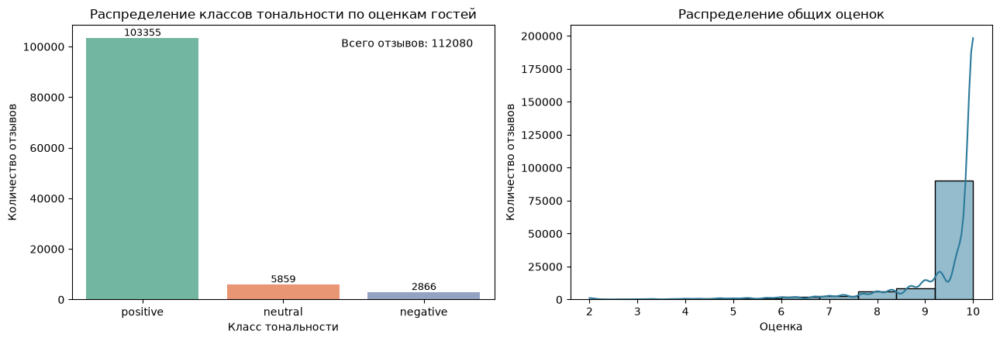

In [58]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sentiment_plot = sentiment_summary.copy()
sns.barplot(
    data=sentiment_plot,
    x="Класс тональности",
    y="Количество",
    hue="Класс тональности",
    legend=False,
    palette="Set2",
    ax=axes[0],
)

# Добавляем значения над каждым столбцом
for p in axes[0].patches:
    height = p.get_height()
    x = p.get_x() + p.get_width() / 2
    y = height
    axes[0].text(
        x, y, f"{int(height)}", ha='center', va='bottom', fontsize=9
    )

total_reviews = len(data)
axes[0].text(
    0.95, 0.95, f"Всего отзывов: {total_reviews}",
    transform=axes[0].transAxes,
    ha='right', va='top',
    fontsize=10,
    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
)
    
axes[0].set_title("Распределение классов тональности по оценкам гостей")
axes[0].set_xlabel("Класс тональности")
axes[0].set_ylabel("Количество отзывов")


rating_values = data['rating'].dropna()
if rating_values.empty:
    axes[1].text(0.5, 0.5, "Нет числовых оценок", ha="center", va="center")
else:
    sns.histplot(rating_values, bins=10, kde=True, color="#2b7a9b", ax=axes[1])
axes[1].set_title("Распределение общих оценок")
axes[1].set_xlabel("Оценка")
axes[1].set_ylabel("Количество отзывов")

plt.tight_layout()
plt.show()

АНАЛИЗ ТОНАЛЬНОСТИ ТЕКСТА ОТЗЫВА

Буду определять тональность текста, то есть, с какой вероятностью интересующий нас текст будет с положительным или же, наоборот, с негативным окрасом. 
Сначала подготавливаю качественные данные для последующего анализа тональности.  

In [61]:
# Функция для очистки текста комментария и делаю токенизацию
def clean_and_tokenize(text):
    # Удаляем знаки препинания
    text = re.sub(r'[^\w\s]', '', text)
    # Удаляем цифры
    text = re.sub(r'\d+', '', text)
    # Переводим в нижний регистр
    text = text.lower()
    # Разбиваем на токены по пробелам
    tokens = text.split()
    return tokens

# Применяю функцию к колонке review_text
data['processed_review'] = data['review_text'].apply(clean_and_tokenize)

In [62]:
morph1 = pymorphy3.MorphAnalyzer()   #создаю объект MorphAnalyzer

In [63]:
def lemmatize_tokens(tokens):  #функция лемматизации 
    lemmatized = [morph1.parse(word)[0].normal_form for word in tokens]
    return lemmatized

# Применяю к колонке, которая уже была очищена и токенизирована
data['processed_review'] = data['processed_review'].apply(lemmatize_tokens)

Воспользуюсь файлом проекта (https://github.com/stopwords-iso/stopwords-ru) и заберу содержимое из ответа на запрос, чтобы создать переменную, где будут стоп слова для русского языка.

In [64]:
url = "https://raw.githubusercontent.com/stopwords-iso/stopwords-ru/refs/heads/master/stopwords-ru.txt"
req = requests.get(url)           # код 200 – ответ получен, все ОК
print(req)
stop_words1 = req.text.split("\n") #по этой ссылке, что достала, заберу сам текст и расщеплю его по переносу, т.к.там кажд.слово было на новой строке 
print(len(stop_words1))       #сколько всего стоп слов
print(stop_words1[0:100])     #вывожу посмотреть первые 100

<Response [200]>
559
['c', 'а', 'алло', 'без', 'белый', 'близко', 'более', 'больше', 'большой', 'будем', 'будет', 'будете', 'будешь', 'будто', 'буду', 'будут', 'будь', 'бы', 'бывает', 'бывь', 'был', 'была', 'были', 'было', 'быть', 'в', 'важная', 'важное', 'важные', 'важный', 'вам', 'вами', 'вас', 'ваш', 'ваша', 'ваше', 'ваши', 'вверх', 'вдали', 'вдруг', 'ведь', 'везде', 'вернуться', 'весь', 'вечер', 'взгляд', 'взять', 'вид', 'видел', 'видеть', 'вместе', 'вне', 'вниз', 'внизу', 'во', 'вода', 'война', 'вокруг', 'вон', 'вообще', 'вопрос', 'восемнадцатый', 'восемнадцать', 'восемь', 'восьмой', 'вот', 'впрочем', 'времени', 'время', 'все', 'все еще', 'всегда', 'всего', 'всем', 'всеми', 'всему', 'всех', 'всею', 'всю', 'всюду', 'вся', 'всё', 'второй', 'вы', 'выйти', 'г', 'где', 'главный', 'глаз', 'говорил', 'говорит', 'говорить', 'год', 'года', 'году', 'голова', 'голос', 'город', 'да', 'давать']


In [66]:
def remove_stopwords(tokens):
    return [token for token in tokens if token not in stop_words1]

data['processed_review'] = data['processed_review'].apply(remove_stopwords)    

In [67]:
data['review_text'].head(10)

0     Гостиница расположена недалеко от метро. Засел...
1     В номере есть всё для комфортного проживания, ...
3     Отель понравился. Хорошее местоположение - до ...
4     Хорошее местоположение - до метро и торгового ...
5     Отдыхала во время новогодних праздников- в гос...
6     Отличный небольшой отель рядом с метро (для ме...
7     Отличная гостиница, все есть. Приветливый перс...
9     Заселение прошло во время. тут же удалось пооб...
10    Чисто, уютно, хороший завтрак. Очень доброжела...
11    Все соответствует заявленному. Мини бар оверпр...
Name: review_text, dtype: str

In [68]:
data['processed_review'].head(10)

0     [гостиница, расположить, метро, заселиться, пр...
1     [номер, комфортный, проживание, чистота, урове...
3     [отель, понравиться, местоположение, метро, то...
4     [местоположение, метро, торговый, комплекс, ме...
5     [отдыхать, новогодний, праздник, гостиница, ат...
6     [отличный, небольшой, отель, метро, важно, оте...
7          [отличный, гостиница, приветливый, персонал]
9     [заселение, пройти, удаться, пообедать, кафе, ...
10    [чисто, уютный, завтрак, доброжелательный, пер...
11     [соответствовать, заявить, минь, бар, оверпрайс]
Name: processed_review, dtype: object

In [69]:
!pip install transformers
!pip install torch
!pip install torch

In [70]:
import torch
from transformers import pipeline
from tqdm import tqdm

Загружаем ниже русскоязычную модель на основе RuBERT, создаём пайплайн с помощью библиотеки Hugging Face Transformers, которая будет определять тональность отзыва.  Модель классифицирует текст по эмоциональной окраске.
'label' — указание на тональность: 'POSITIVE' (положительная) или 'NEGATIVE' (отрицательная), 'NEUTRAL' (нейтральная).
'score' — вероятность или оценка уверенности модели в этом выводе (число от 0 до 1).

In [71]:
sentiment_pipeline = pipeline("sentiment-analysis", model="blanchefort/rubert-base-cased-sentiment") 

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [72]:
# Создаем списки для результатов
sentiments = []
scores = []

# Обрабатываем по одному с прогресс-баром
for text in tqdm(data['review_text'], desc="Обработка отзывов"):
    result = sentiment_pipeline(text, max_length=512, truncation=True)[0]
    sentiments.append(result['label'])
    scores.append(result['score'])

# Записываем результаты обратно в DataFrame
data['sentiment'] = sentiments
data['score'] = scores

Обработка отзывов: 100%|██████████| 112080/112080 [3:05:44<00:00, 10.06it/s] 


In [74]:
data.shape  

(112080, 39)

In [75]:
data.head(3)

,review_id,object_id,object_name,object_type,object_address,city,object_url,source_url,author,author_avatar_url,...,text_words,sentiment_target,language_hint,scraped_at_utc,clean_comment,topic,topic_weight,processed_review,sentiment,score
0,331689291,1319021,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Владимир,https://static.sutochno.ru/doc/files/users/5/8...,...,27,positive,ru,2026-09-16T18:16:43+00:00,"[гостиница, расположить, недалеко, метро, засе...",Впечатления от отдыха,0.406409,"[гостиница, расположить, метро, заселиться, пр...",POSITIVE,0.985691
1,331688111,1319021,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Пользователь предпочёл скрыть свои данные,https://static.sutochno.ru/doc/i/default-avata...,...,25,positive,ru,2026-09-16T18:16:43+00:00,"[номер, всё, комфортный, проживание, чистота, ...",Впечатления от отдыха,0.906877,"[номер, комфортный, проживание, чистота, урове...",POSITIVE,0.980763
3,331220376,1319021,"Одноместный номер стандарт, Москва, Гарибальди...",Одноместный номер стандарт,,,https://sutochno.ru/front/searchapp/detail/131...,https://www.sutochno.ru/1319021,Никита,https://static.sutochno.ru/doc/i/default-avata...,...,76,positive,ru,2026-09-16T18:16:43+00:00,"[отель, понравиться, хороший, местоположение, ...",Расположение и инфраструктура,0.404447,"[отель, понравиться, местоположение, метро, то...",POSITIVE,0.981163


Визуализируем полученные с помощью модели результаты.

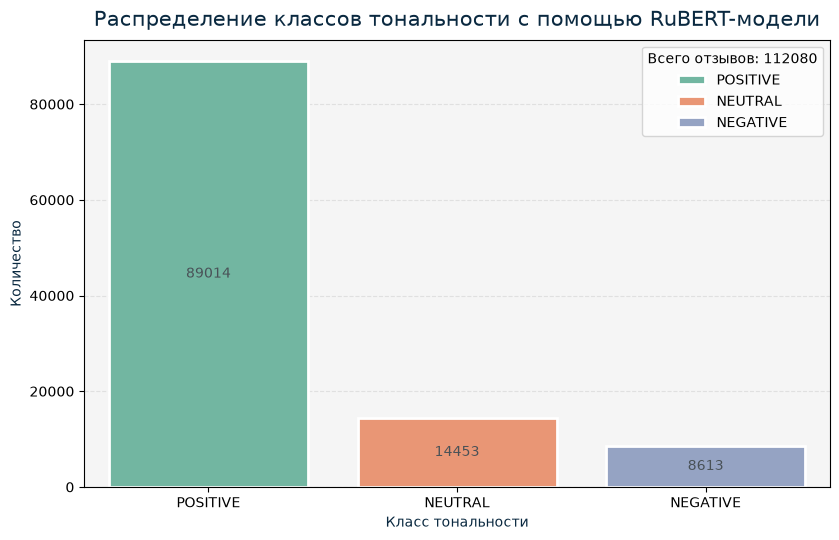

In [76]:
total = len(data["sentiment"])

plt.figure(figsize = (8.5, 5.5))
ax = plt.gca()
ax.set_facecolor('#F5F5F5')

sns.countplot(
    data = data,
    x = 'sentiment',
    hue = 'sentiment',
    palette = 'Set2',
    legend=True,
    edgecolor = 'white',
    linewidth = 2,
    zorder=2
)

for value in ax.containers:
    ax.bar_label(value, fmt = '%d', fontsize = 10, color = '#495157', label_type = 'center')

ax.legend(title=f"Всего отзывов: {total}")

plt.title('Распределение классов тональности с помощью RuBERT-модели', fontsize = 15, color = '#0A2940', pad = 10)
plt.xlabel('Класс тональности', fontsize = 10, color = '#0A2940')
plt.ylabel('Количество', fontsize = 10, color = '#0A2940')

plt.grid(linestyle = '--', alpha = 0.3)
ax.grid(zorder = 0)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Построим визуализации на одном полотне для наглядного сравнения по количеству отзывов. Первый график - распределние классов просто на основе оценок, второй распределение классов с помощью модели RuBERT, которая классифицирует текст отзыва по эмоциональной окраске. И посмотрим доли. 
Наблюдаем ниже, что оценки по сайту и RuBERT дают заметно разные распределения тональности. Оценка может отражать в целом удовлетворённость проживанием, а текст — содержать жалобы, критику или смешанные эмоции по конкретной услуги.

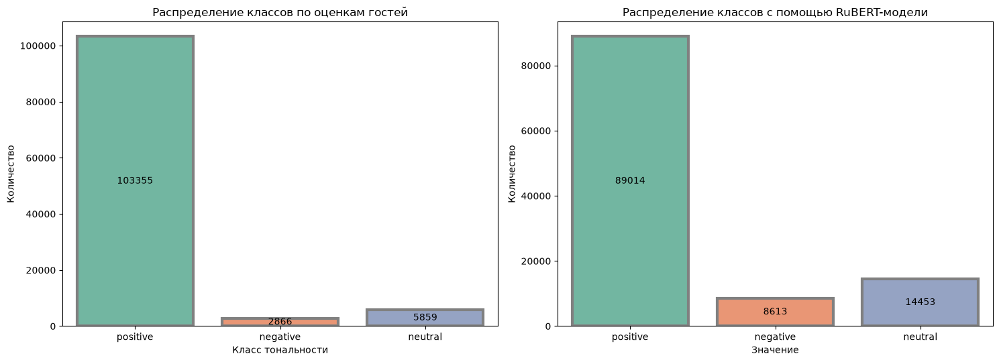

In [77]:
order = ["positive", "negative", "neutral"] #задаем порядок, чтобы было удобно наглядно смотреть
data["sentiment"] = (data["sentiment"].astype("string").str.lower())
                                 
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.countplot(data=data, x="sentiment_target", hue="sentiment_target", order=order, hue_order=order, edgecolor = 'gray', linewidth = 3,
              palette="Set2", ax=axes[0])
axes[0].set_title("Распределение классов по оценкам гостей")
axes[0].set_xlabel("Класс тональности")
axes[0].set_ylabel("Количество")


sns.countplot(data=data, x="sentiment", hue="sentiment", order=order, hue_order=order, edgecolor = 'gray', linewidth = 3,
              palette="Set2", ax=axes[1])
axes[1].set_title("Распределение классов с помощью RuBERT-модели")
axes[1].set_xlabel("Значение")
axes[1].set_ylabel("Количество")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", label_type="center", fontsize=10)

plt.tight_layout()
plt.show()

In [78]:
order = ["positive", "negative", "neutral"]

for col in ["sentiment_target", "sentiment"]:
    values = data[col].astype("string").str.lower()
    share = values.value_counts(normalize=True, dropna=False).reindex(order, fill_value=0) * 100
    print(f"\nДоля каждого класса в колонке {col}:")
    print("\n".join(f"{label}: {percent:.2f} %" for label, percent in share.items()))


Доля каждого класса в колонке sentiment_target:
positive: 92.22 %
negative: 2.56 %
neutral: 5.23 %

Доля каждого класса в колонке sentiment:
positive: 79.42 %
negative: 7.68 %
neutral: 12.90 %


ПОСТРОЕНИЕ МОДЕЛИ КЛАССИФИКАЦИИ

Построим модель для определения тональности отзывов. Модель сначала переводит слова и пары соседних слов в числовые признаки (TF‑IDF), затем логистическая регрессия использует их для классификации.

In [79]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [80]:
X = data['review_text'].astype(str)
y = data['sentiment_target'] 

In [81]:
X_train, X_test, y_train, y_test = train_test_split( X, y, 
                                                     test_size=0.3,random_state=42, stratify=y) #осуществляем разбиение

In [82]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(      # первый этап: преобразует текст в числовые признаки с помощью TF-IDF
        ngram_range=(1, 2),         # учитывает отдельные слова и пары соседних слов
        max_features=100_000,       # оставляет не более 100 000 признаков (слов и пар слов)
        min_df=2)),                 # игнорирует слова и пары, встречающиеся менее чем в двух документах.
    ("classifier", LogisticRegression(    # второй этап: классификатор, который использует полученные числовые признаки
        max_iter=1000,                    # разрешает алгоритму сделать до 1000 итераций при поиске решения
        class_weight="balanced"))])       # автоматически увеличивает вес менее частых классов, что полезно при несбалансированных данных

In [83]:
model.fit(X_train, y_train)               #обучение

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",100000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [84]:
predictions = model.predict(X_test)      # предсказание         
print(classification_report(y_test, predictions))   #оценка качества 

              precision    recall  f1-score   support

    negative       0.51      0.60      0.55       860
     neutral       0.30      0.63      0.41      1758
    positive       0.99      0.92      0.95     31006

    accuracy                           0.90     33624
   macro avg       0.60      0.72      0.64     33624
weighted avg       0.94      0.90      0.91     33624



Заметная разница между macro avg и weighted avg связана скорее всего с дисбалансом классов: positive составляет 31006 из 33624 примеров, а neutral и negative встречаются гораздо реже. Поэтому accuracy и weighted avg в основном отражают качество на классе positive. Для оценки редких классов смотрим на их отдельные метрики и macro avg. Neutral recall = 0.63 означает, что модель нашла 63% всех настоящих нейтральных примеров, но precision = 0.30, то есть среди всех примеров, которые модель назвала нейтральными, верны лишь 30% — она часто ошибается, присваивая этот класс. Macro avg усредняет показатели трёх классов поровну, поэтому показывает качество без доминирования многочисленного класса positive. Также, macro F1 = 0.64, что заметно ниже чем weighted F1 = 0.91, это указывает, что качество на редких классах существенно хуже, чем на основном. В целом модель хорошо распознаёт positive, но плохо различает редкие классы — особенно neutral. Поэтому высокая accuracy = 0.90 — модель верно классифицировала 90% примеров, здесь создаёт слишком оптимистичное впечатление, поскольку данных класса positive подавляющее большинство. 
_______________________________________________________________________________________________________________________________________________________
precision — среди всех примеров, которые модель отнесла к классу, какая доля действительно принадлежит этому классу
recall — среди всех настоящих примеров класса какую долю модель нашла
f1-score — баланс между precision и recall
support — количество настоящих примеров этого класса в y_test
accuracy — доля всех верных предсказаний
macro avg — среднее по классам без учёта их размера
weighted avg — среднее по классам с учётом количества примеров каждого класса

In [85]:
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

In [86]:
metrics.confusion_matrix(y_test,  predictions) # смотрим на матрицу ошибок

array([[  516,   302,    42],
       [  282,  1099,   377],
       [  218,  2254, 28534]])

Класс negative: верно 516, ошибочно предсказан как neutral — 302 раза и как positive — 42 раза.
Класс neutral: верно 1099, ошибочно как negative — 282 и как positive — 377 раз.
Класс positive: верно 28534, но 2254 примера ошибочно отнесены к классу neutral и 218 примеров ошибочно к классу negative.
Всего верно классифицировано 30 149 из 33 624 примеров — точность около 90%.

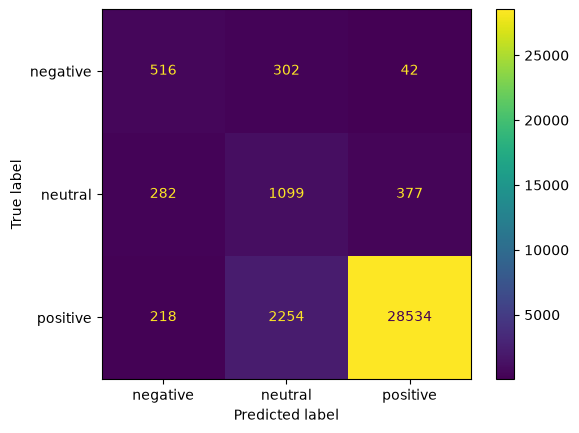

In [87]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=model.classes_) #выводим матрицу ошибок 

Посмотрим на визуализации какие же признаки (слова) наиболее важны при разделении на отзывы с более высоким рейтингом и на отзывы с более низким рейтингом!

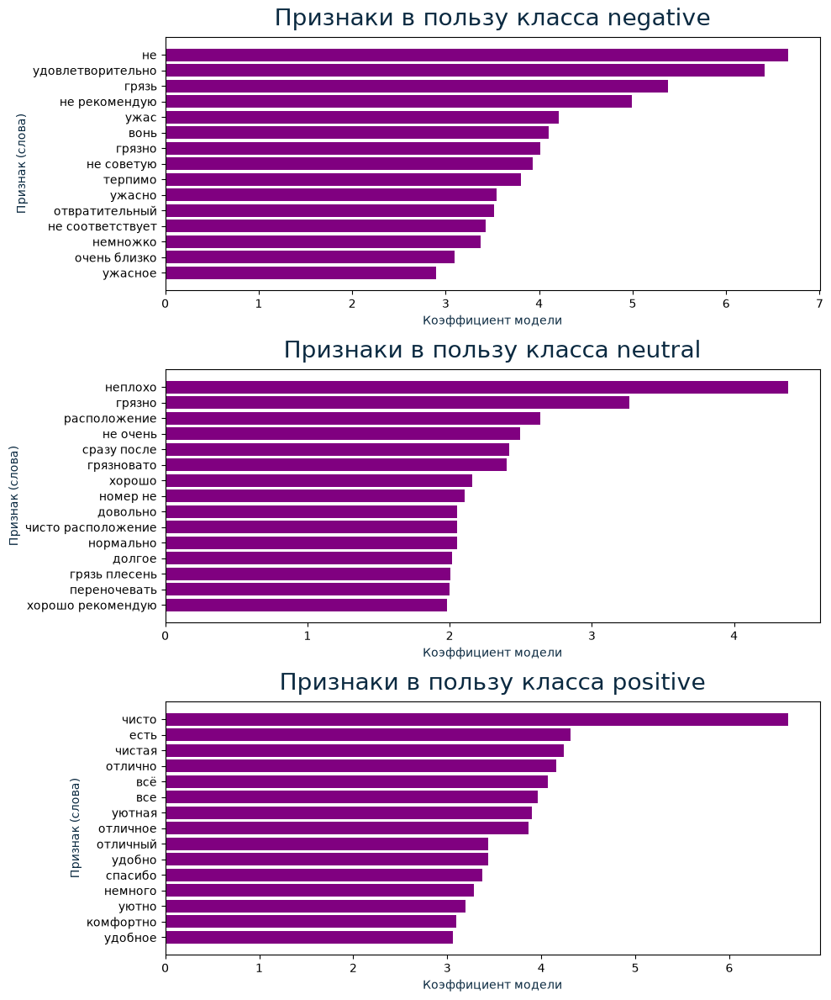

In [88]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

words = vectorizer.get_feature_names_out()
classes = classifier.classes_
top_n = 15

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=1,
    figsize=(10, 4 * len(classes)),
    squeeze=False
)

for i, class_name in enumerate(classes):
    coefs = classifier.coef_[i]
    # Индексы top_n признаков с наибольшими положительными коэффициентами
    top_idx = coefs.argsort()[-top_n:][::-1]

    dt = pd.DataFrame({
        "слово/фраза": words[top_idx],
        "коэффициент": coefs[top_idx]
    }).sort_values("коэффициент")

    ax = axes[i, 0]
    ax.barh(dt["слово/фраза"], dt["коэффициент"], color="purple")
    ax.set_title(f"Признаки в пользу класса {class_name}", fontsize = 20, color = '#0A2940', pad = 10)
    ax.set_xlabel("Коэффициент модели", fontsize = 10, color = '#0A2940')
    ax.set_ylabel("Признак (слова)", fontsize = 10, color = '#0A2940')

plt.tight_layout()
plt.show()

Определяем темы и % отзывов, которые относятся к негативным и нейтральным отзывам по оценкам гостей и смотрим процентное соотношение негативных и нейтральных отзывов по каждой теме.

In [89]:
shares_rating = (
    data.assign(
        negative=data["rating"] < 6,
        neutral=data["rating"].between(6, 8, inclusive="left")
    )
    .groupby("topic")[["negative", "neutral"]]
    .mean()
    .mul(100)
    .round(1)
)

print(shares_rating)

                                      negative  neutral
topic                                                  
Благодарность за проживание хозяевам       2.8      3.0
Впечатления от отдыха                      0.1      0.8
Организация заселения и проживания        13.9     16.0
Расположение и инфраструктура              0.1      1.4
Состояние и оснащение квартиры             5.9     17.0


Большая часть негативных и нейтральных отзывов по оценкам гостей связана с темой организация заселения и проживания, а также гости жалуются на состояние и оснащение квартиры.

Определяем темы и % отзывов, которые относятся к негативным и нейтральным отзывам согласно построенной ранее RuBERT-модели.

In [90]:
shares_rubert = (
    data.assign(
        negative_rubert = data["sentiment"].eq("negative"),
        neutral_rubert = data["sentiment"].eq("neutral")
    )
    .groupby("topic")[["negative_rubert", "neutral_rubert"]]
    .mean()
    .mul(100)
    .round(1)
)

print(shares_rubert)

                                      negative_rubert  neutral_rubert
topic                                                                
Благодарность за проживание хозяевам              2.7            14.6
Впечатления от отдыха                             2.1             8.3
Организация заселения и проживания               25.9            18.7
Расположение и инфраструктура                     2.0            11.3
Состояние и оснащение квартиры                   21.3            24.3


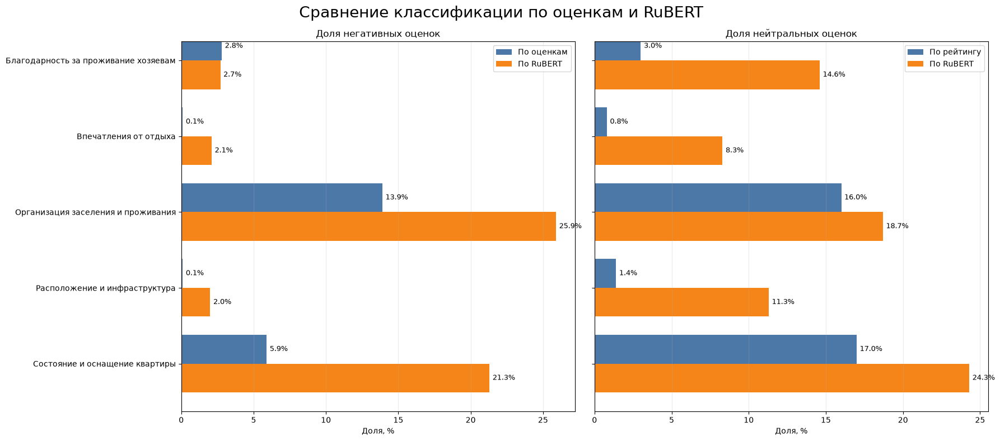

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

shares_rating["negative"].plot(
    kind="barh", ax=axes[0], position=1, width=0.38,
    color="#4C78A8", label="По оценкам"
)
shares_rubert["negative_rubert"].rename("По RuBERT").plot(
    kind="barh", ax=axes[0], position=0, width=0.38,
    color="#F58518", label="По RuBERT"
)
axes[0].set_title("Доля негативных оценок")
axes[0].set_xlabel("Доля, %")
axes[0].set_ylabel("")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.25)

shares_rating["neutral"].plot(
    kind="barh", ax=axes[1], position=1, width=0.38,
    color="#4C78A8", label="По рейтингу"
)
shares_rubert["neutral_rubert"].rename("По RuBERT").plot(
    kind="barh", ax=axes[1], position=0, width=0.38,
    color="#F58518", label="По RuBERT"
)
axes[1].set_title("Доля нейтральных оценок")
axes[1].set_xlabel("Доля, %")
axes[1].set_ylabel("")
axes[1].legend()
axes[1].grid(axis="x", alpha=0.25)

for ax in axes:
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{value:.1f}%" for value in container.datavalues],
            padding=4,
            fontsize=9
        )

topics = shares_rating.index.tolist()
axes[0].set_yticks(range(len(topics)))
axes[0].set_yticklabels(topics)
axes[0].invert_yaxis()

fig.suptitle("Сравнение классификации по оценкам и RuBERT", fontsize=20)
plt.tight_layout()
plt.show()

Модель RuBERT относит к негативным больше отзывов, чем подход, основанный на оценках гостей, в четырёх из пяти тем (исключение благодарность за проживаение). Наиболее заметное расхождение наблюдается в темах — «Состояние и оснащение квартиры» (21,3% против 5,9%) и «Организация заселения и проживания» (25,9% против 13,9%).  
Доля нейтральных отзывов по RuBERT существенно больше во всех темах. Наибольшие значения наблюдаются для состояния и оснащения квартиры (24,3%) и организация заселения и проживания (18,7%). Особенно заметно расхождение по теме благодарности хозяевам: RuBERT значительно чаще относит такие отзывы к нейтральным.
Показатели двух способов оценки сильно расходятся, поэтому их нельзя напрямую считать взаимозаменяемыми. Оценка гостя — числовая оценка всего проживания, а RuBERT классифицирует тональность текста; в одном отзыве могут сочетаться высокая оценка и критика отдельного аспекта. RuBERT значительно чаще выявляет негатив и нейтральность, чем это видно по оценкам гостей. Значит, модель улавливает критические нюансы текста, которые не всегда отражаются в общей оценке проживания.

Общие направления для улучшения сервиса:
1. Состояние и оснащение квартиры — нужно проверить дополнительно отзывы этой темы вручную. Если модель верно определила тональность, то стоит обратить внимание на чистоту, исправность техники, мебель и соответствие описанию. 
2. Организация заселения и проживания — изучить жалобы на инструкции по заселению, передачу ключей, связь с хозяином, решение проблем во время проживания. Эта тема заметна и по доле негативных, и по доле нейтральных отзывов RuBERT, а также и по оценкам гостей.

Общие выводы по проделанной работе: проведён комплексный анализ отзывов Суточно.ру: определены их тональность и основные темы, выделены признаки (слова), характерные для разных классов, а также сопоставлены результаты RuBERT с оценками гостей. Анализ показал, что числовая оценка проживания и тональность текста отражают разные стороны впечатления и не являются взаимозаменяемыми: RuBERT чаще выявляет негативные и нейтральные формулировки, чем это следует из оценок. Наиболее заметные направления для дополнительной проверки — состояние и оснащение жилья и организация заселения и проживания.Таким образом, анализ текста отзывов дополняет числовые оценки гостей и помогает выявлять конкретные аспекты проживания, требующие внимания. Полученные результаты могут использоваться для определения направлений улучшения сервиса и более точного понимания причин недовольства пользователей.

In [102]:
data.to_csv("final_dataset.csv", index=False, encoding="utf-8-sig") #сохранение датасета